# Practical - steer Snake with your thumb

You will train networks that read **which way your thumb points** in a webcam crop - up, down,
left, right, or nothing - and then play Snake with the best one (`play_snake.py`).

| Part | What you do |
|---|---|
| 1 | look at your own recordings |
| 2 | split by **burst**, not at random |
| 3 | a small CNN from scratch, and where it fails |
| 3b | the same task with a plain ANN - no convolutions |
| 3c | a bigger CNN, and the three networks side by side |
| 4 | **error analysis**: what is different between your training and validation data? |
| 5 | Grad-CAM: is it looking at your thumb? ([50]) |
| 6 | augmentation as an experiment - including one that **changes the label** |
| 7 | the random-split trap, measured |
| 8 | transfer learning: frozen ResNet-18 features + logistic regression ([50]) |
| 8b | fine-tuning: retrain ResNet-18's last conv layer - from the probe, and from scratch |
| 9 | feature extraction with CLIP, and CLIP zero-shot |
| 10 | other people: does it work on strangers? |
| 11 | export the model and play |

**Before you start:** record your data (about 3 minutes, two bursts per class):

```
python record_gestures.py --user yourname
```

Everything runs on a laptop CPU. Seed `509`. A full run takes **about 13 minutes for 500 images on
2 CPU threads** (measured 753 s on the instructor's recordings). More recordings make it slower,
more cores faster.

The outputs saved in this notebook come from the **instructor's** recordings: 500 crops, 2 bursts
per class. The notes after the results describe that run - yours will differ.

## Setup

`gesture_common.py` is shared by the recorder, this notebook and the game: the class list, the
crop, and the image-to-tensor conversion all come from there, so the three can never disagree.

In [1]:
# ~12 s: the first import of torch, plotly and sklearn is slow
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
import torch.nn as nn
import torch.nn.functional as F
from plotly.subplots import make_subplots

from gesture_common import CLASSES, CROP_SIZE, bgr_to_tensor, imread_u, parse_name

SEED = 509
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
DATA = Path("gesture_data")
ARM_RED, ARM_BLUE, ARM_ORANGE = "#D90012", "#0033A0", "#F2A800"
print("classes:", CLASSES, "| crop:", CROP_SIZE, "px | torch", torch.__version__)

classes: ('up', 'down', 'left', 'right', 'nothing') | crop: 128 px | torch 2.9.0+cpu


## Part 1 - your data

Every file name carries three facts: `gesture_data/<user>/<class>/<user>_<burst>_<nn>.jpg`.
The **burst** is one key press in the recorder: 50 frames taken over about 5 seconds.

In [2]:
files = sorted(DATA.glob("*/*/*.jpg"))
if not files:
    raise FileNotFoundError(f"no images under {DATA.resolve()} - run record_gestures.py first")
meta = [parse_name(f) for f in files]
X = np.stack([imread_u(f) for f in files])                  # (N, 128, 128, 3), uint8, BGR
y = np.array([CLASSES.index(c) for _, _, c in meta], dtype=np.int64)  # int64: what the loss wants
users = np.array([u for u, _, _ in meta])
bursts = np.array([f"{u}/{c}/{b}" for u, b, c in meta])
missing = [c for c in CLASSES if c not in {m[2] for m in meta}]
if missing:
    raise ValueError(f"no recordings for {missing} - record every class")
print(f"{len(X)} images, {X.nbytes / 1e6:.0f} MB in memory, {len(set(bursts))} bursts, "
      f"{len(set(users))} user(s)")

500 images, 25 MB in memory, 10 bursts, 1 user(s)


One file, taken apart. The image itself is a plain array: height x width x 3 colour channels,
whole numbers from 0 to 255, in OpenCV's **BGR** order (blue first).

In [3]:
print("file:          ", files[0].as_posix())
print("user, burst, class:", parse_name(files[0]))
print("label:         ", y[0], "=", CLASSES[y[0]])
print("image array:   ", X[0].shape, X[0].dtype, "| values from", X.min(), "to", X.max())

file:           gesture_data/hayk/down/hayk_20261001-202905_00.jpg
user, burst, class: ('hayk', '20261001-202905', 'down')
label:          1 = down
image array:    (128, 128, 3) uint8 | values from 0 to 207


How many images per user and class:

In [4]:
pd.crosstab(pd.Series(users, name="user"),
            pd.Series([CLASSES[k] for k in y], name="class"))[list(CLASSES)]

class,up,down,left,right,nothing
user,,,,,
hayk,100,100,100,100,100


The classes are balanced, so a model that guesses at random is right **20%** of the time - the
line every accuracy below has to clear.

Eight random crops per class. This is exactly what the model will see - the green box of the
recorder, mirrored like a selfie.

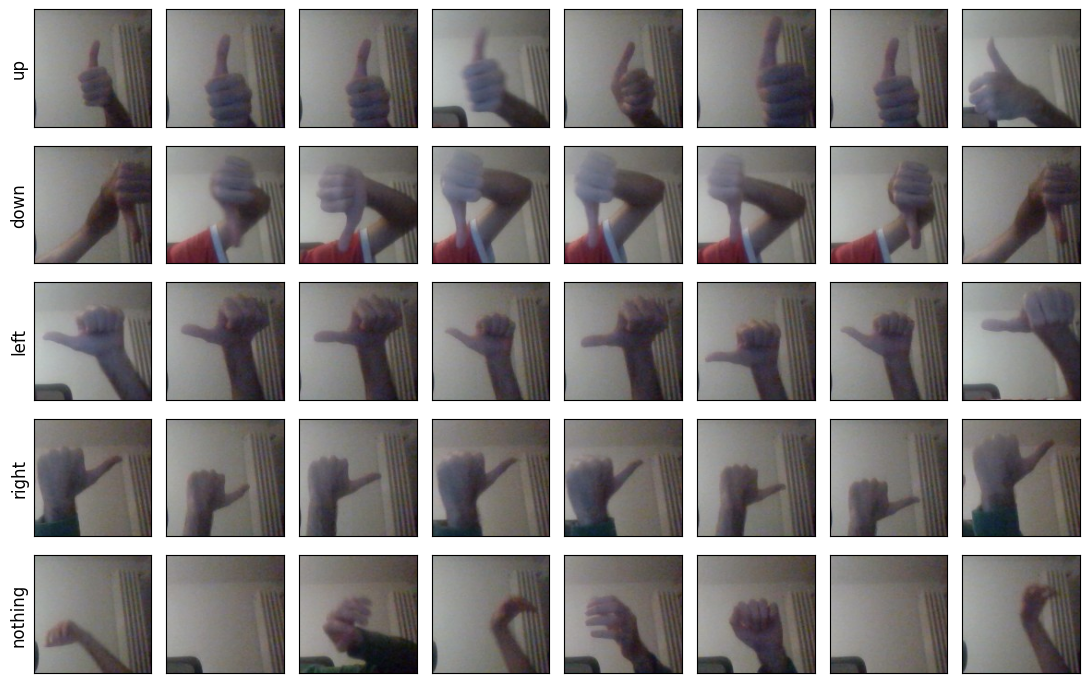

In [5]:
# ~3 s
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(11, 7))
for r, c in enumerate(CLASSES):
    pick = rng.choice(np.where(y == r)[0], 8, replace=False)
    for ax, i in zip(axes[r], pick):
        ax.imshow(X[i][..., ::-1])        # BGR -> RGB for matplotlib
        ax.set_xticks([])
        ax.set_yticks([])
    axes[r, 0].set_ylabel(c, fontsize=12)
plt.tight_layout()
plt.show()

Look past the thumbs, at everything else in the box: the sleeves, the wall, the radiator, the
corners. A network sees all of it, and nothing tells it that only the thumb matters. Part 4 comes
back to this.

## Part 2 - split by burst

Frames inside one burst are a tenth of a second apart: near-copies. See for yourself - every fifth
frame of one burst:

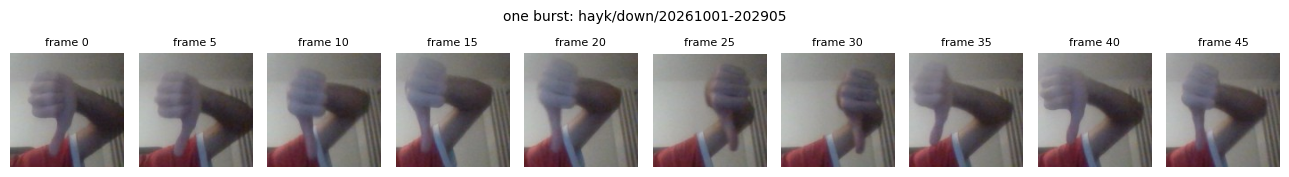

In [6]:
first_burst = bursts[0]
frames = np.where(bursts == first_burst)[0]
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for ax, i in zip(axes, frames[::5]):
    ax.imshow(X[i][..., ::-1])
    ax.set_title(f"frame {i - frames[0]}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"one burst: {first_burst}", fontsize=10)
plt.tight_layout()
plt.show()

Five seconds, one gesture, one sleeve, one background: the frames differ by a little hand motion and
nothing else. To a network, these 50 frames are closer to **one** example than to 50.

If a random split puts one of these frames in training and its neighbour in validation, the
validation score measures **memory**, not skill. (The popular Kaggle ASL alphabet set is 3,000
consecutive video frames per letter, one signer, one room; models that look near-perfect on it are
reported to fail on new backgrounds.)

So we hold out **whole bursts**: for every user and class, the last burst goes to validation.

In [7]:
def burst_split(users, y, bursts):
    # returns (train indices, validation indices): the last burst of every user and class validates
    val_mask = np.zeros(len(y), dtype=bool)
    for u in np.unique(users):
        for k, c in enumerate(CLASSES):
            bs = sorted(set(bursts[(users == u) & (y == k)]))
            if len(bs) < 2:
                raise ValueError(f"{u}/{c} has {len(bs)} burst(s) - record at least 2 so one can be held out")
            val_mask |= bursts == bs[-1]
    return np.where(~val_mask)[0], np.where(val_mask)[0]


tr, va = burst_split(users, y, bursts)
assert not set(bursts[tr]) & set(bursts[va]), "a burst must never be on both sides"
print(f"train {len(tr)} images | validation {len(va)} images (whole bursts)")

train 250 images | validation 250 images (whole bursts)


Where every burst went - each one lands entirely on one side:

In [8]:
side = np.full(len(y), "train", dtype=object)
side[va] = "validation"
pd.crosstab(pd.Series(bursts, name="burst"), pd.Series(side, name="goes to"))

goes to,train,validation
burst,,
hayk/down/20261001-202905,50,0
hayk/down/20261001-220258,0,50
hayk/left/20261001-202922,50,0
hayk/left/20261001-220306,0,50
hayk/nothing/20261001-202959,50,0
hayk/nothing/20261001-220326,0,50
hayk/right/20261001-202948,50,0
hayk/right/20261001-220316,0,50
hayk/up/20261001-202853,50,0


Every class is learned from **one** burst and tested on **one** other burst. Keep that in mind when
reading the scores below: the validation set is 250 crops, but only 5 independent recordings - when
one of them goes wrong, the score moves by 20 points at once.

## Part 3 - a small CNN

The crop is 128 px; a thumb is obvious at 64 px, so the net first **averages 2x2 blocks** (a
pooling layer with no weights, [48]). Then three conv blocks - conv, BatchNorm, ReLU, max-pool -
each halving the map and doubling the channels, down to 64 maps of 8x8.

The head is a dense layer on the **flattened** 8x8x64 maps, not [49]'s global average pool. A
global average pool keeps only "how much of each feature", and which way a thumb points is a
question about *where*: which side of the fist the thumb sticks out.

One layer per line; the comment says the shape that comes out, as (channels, height, width).

In [9]:
def small_cnn():
    return nn.Sequential(
        nn.AvgPool2d(2),                      # (3, 128, 128) -> (3, 64, 64)

        nn.Conv2d(3, 16, 3, padding=1),       # block 1 -> (16, 64, 64)
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (16, 32, 32)

        nn.Conv2d(16, 32, 3, padding=1),      # block 2 -> (32, 32, 32)
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (32, 16, 16)

        nn.Conv2d(32, 64, 3, padding=1),      # block 3 -> (64, 16, 16)
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (64, 8, 8)

        nn.Flatten(),                         # -> 4,096 numbers
        nn.Linear(64 * 8 * 8, len(CLASSES)),  # -> 5 class scores (logits)
    )

Do not trust the comments - check them. Push one blank crop through the layers one at a time and
print the shape and the number of weights after each:

In [10]:
def show_shapes(model):
    x = torch.zeros(1, 3, CROP_SIZE, CROP_SIZE)
    print(f"{'':>2}  {'layer':<12} {'output shape':<16} {'weights':>9}")
    print(f"{'':>2}  {'input':<12} {str(tuple(x.shape[1:])):<16}")
    model.eval()
    with torch.no_grad():
        for i, layer in enumerate(model):
            x = layer(x)
            n = sum(p.numel() for p in layer.parameters())
            print(f"{i:>2}  {type(layer).__name__:<12} {str(tuple(x.shape[1:])):<16} {n:>9,}")
    print(f"total weights: {sum(p.numel() for p in model.parameters()):,}")


show_shapes(small_cnn())

    layer        output shape       weights
    input        (3, 128, 128)   
 0  AvgPool2d    (3, 64, 64)              0
 1  Conv2d       (16, 64, 64)           448
 2  BatchNorm2d  (16, 64, 64)            32


 3  ReLU         (16, 64, 64)             0
 4  MaxPool2d    (16, 32, 32)             0
 5  Conv2d       (32, 32, 32)         4,640
 6  BatchNorm2d  (32, 32, 32)            64
 7  ReLU         (32, 32, 32)             0
 8  MaxPool2d    (32, 16, 16)             0
 9  Conv2d       (64, 16, 16)        18,496
10  BatchNorm2d  (64, 16, 16)           128
11  ReLU         (64, 16, 16)             0
12  MaxPool2d    (64, 8, 8)               0
13  Flatten      (4096,)                  0
14  Linear       (5,)                20,485
total weights: 44,293


Check that total with [48]'s formula, $k \cdot k \cdot C_{in} \cdot C_{out} + C_{out}$ per conv, plus
$2 C$ per BatchNorm ($\gamma$, $\beta$) and $64 \cdot 8 \cdot 8 \cdot 5 + 5$ for the head:

In [11]:
def conv_weights(k, cin, cout):
    return k * k * cin * cout + cout


by_hand = (conv_weights(3, 3, 16) + conv_weights(3, 16, 32) + conv_weights(3, 32, 64)
           + 2 * (16 + 32 + 64)                  # BatchNorm
           + 64 * 8 * 8 * 5 + 5)                 # head
assert by_hand == sum(p.numel() for p in small_cnn().parameters()), "the formula and the model disagree"
print(f"{by_hand:,} - almost half of them in the head")

44,293 - almost half of them in the head


**Training tools.** `predict` returns the predicted class of every image. `evaluate` returns the
average loss and the accuracy on a set of crops, without touching the weights. We call it on the training set and on the validation set alike, so the two numbers are
measured the same way and can be compared directly.

In [12]:
def predict(model, imgs, bs=256):
    # predicted class index for every image in imgs
    model.eval()
    preds = []
    with torch.no_grad():
        for s in range(0, len(imgs), bs):
            logits = model(bgr_to_tensor(imgs[s:s + bs]))
            preds.append(logits.argmax(1))
    return torch.cat(preds).numpy()


def evaluate(model, idx, bs=256):
    # (average loss, accuracy) on the crops X[idx], without any weight updates
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for s in range(0, len(idx), bs):
            b = idx[s:s + bs]
            logits = model(bgr_to_tensor(X[b]))
            labels = torch.from_numpy(y[b])
            total_loss += F.cross_entropy(logits, labels, reduction="sum").item()
            correct += (logits.argmax(1) == labels).sum().item()
    return total_loss / len(idx), correct / len(idx)

The training loop is [42]'s: shuffle, cut into batches of 32, forward, loss, backward, step. After
every epoch it evaluates both sets and prints one line. Every model below gets the same loop and
the same batch order, so differences come from the model.

In [13]:
def train(model, tr_idx, va_idx, epochs=20, lr=2e-3, bs=32, augment=None):
    order_rng = np.random.default_rng(SEED)           # the same batch order for every model
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = []
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train()
        order = order_rng.permutation(tr_idx)
        for s in range(0, len(order), bs):
            b = order[s:s + bs]
            xb, yb = bgr_to_tensor(X[b]), torch.from_numpy(y[b])
            if augment is not None:                    # off until Part 6
                xb, yb = augment(xb, yb)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()

        train_loss, train_acc = evaluate(model, tr_idx)
        val_loss, val_acc = evaluate(model, va_idx)
        hist.append({"epoch": ep, "train loss": train_loss, "val loss": val_loss,
                     "train accuracy": train_acc, "val accuracy": val_acc})
        elapsed = time.perf_counter() - t0
        print(f"epoch {ep:2d}/{epochs} | loss: train {train_loss:.3f}, val {val_loss:.3f} "
              f"| accuracy: train {train_acc:6.1%}, val {val_acc:6.1%} "
              f"| {elapsed:3.0f} s, ~{elapsed / ep * (epochs - ep):.0f} s left")
    return pd.DataFrame(hist)


def report(name, hist, seconds):
    last = hist.iloc[-1]
    best = hist.loc[hist["val accuracy"].idxmax()]
    print(f"{name}: trained in {seconds:.0f} s | last epoch: train accuracy {last['train accuracy']:.1%}, "
          f"val accuracy {last['val accuracy']:.1%} | best val accuracy {best['val accuracy']:.1%} "
          f"(epoch {int(best['epoch'])})")

Two plotting helpers, used for every model below. The training curves come as **two panels**:
the two losses on the left, the two accuracies on the right - each panel compares like with like.

In [14]:
def plot_history(hist, title):
    fig = make_subplots(rows=1, cols=2, subplot_titles=("loss (lower is better)",
                                                        "accuracy (higher is better)"))
    for split, name, color in [("train", "train", ARM_BLUE), ("val", "validation", ARM_RED)]:
        fig.add_scatter(x=hist["epoch"], y=hist[f"{split} loss"], name=name, line_color=color,
                        legendgroup=split, row=1, col=1)
        fig.add_scatter(x=hist["epoch"], y=hist[f"{split} accuracy"], name=name, line_color=color,
                        legendgroup=split, showlegend=False, row=1, col=2)
    fig.add_hline(y=1 / len(CLASSES), line_dash="dot", line_color="gray", row=1, col=2,
                  annotation_text="guessing (20%)", annotation_position="bottom right")
    fig.update_xaxes(title_text="epoch")
    fig.update_yaxes(range=[0, 1.05], tickformat=".0%", row=1, col=2)
    fig.update_layout(height=340, title=title, margin=dict(t=70))
    fig.show()


def confusion(pred, true):
    return pd.crosstab(pd.Series([CLASSES[k] for k in true], name="true"),
                       pd.Series([CLASSES[k] for k in pred], name="predicted")).reindex(
                       index=list(CLASSES), columns=list(CLASSES), fill_value=0)


def heatmap(cm):
    return go.Heatmap(z=cm.values, x=list(CLASSES), y=list(CLASSES), text=cm.values,
                      texttemplate="%{text}", colorscale="Blues", showscale=False)

Train it. One line per epoch - watch the training loss head for zero while the validation loss
does not follow.

In [15]:
# ~40-70 s for 250 training crops on 2 CPU threads (measured 40 s); more recordings, longer
torch.manual_seed(SEED)
cnn = small_cnn()
t0 = time.perf_counter()
hist_cnn = train(cnn, tr, va)
time_cnn = time.perf_counter() - t0
acc_cnn = hist_cnn["val accuracy"].iloc[-1]
report("small CNN", hist_cnn, time_cnn)

epoch  1/20 | loss: train 1.495, val 1.609 | accuracy: train  22.0%, val  22.4% |   2 s, ~38 s left


epoch  2/20 | loss: train 1.321, val 1.610 | accuracy: train  59.6%, val  23.6% |   4 s, ~33 s left


epoch  3/20 | loss: train 1.014, val 1.871 | accuracy: train  60.0%, val  20.0% |   5 s, ~29 s left


epoch  4/20 | loss: train 0.418, val 1.921 | accuracy: train  90.8%, val  27.6% |   7 s, ~28 s left


epoch  5/20 | loss: train 0.082, val 1.970 | accuracy: train 100.0%, val  30.8% |   9 s, ~27 s left


...

epoch 16/20 | loss: train 0.000, val 3.346 | accuracy: train 100.0%, val  46.0% |  29 s, ~7 s left


epoch 17/20 | loss: train 0.000, val 3.382 | accuracy: train 100.0%, val  46.0% |  31 s, ~5 s left


epoch 18/20 | loss: train 0.000, val 3.386 | accuracy: train 100.0%, val  46.0% |  32 s, ~4 s left


epoch 19/20 | loss: train 0.000, val 3.424 | accuracy: train 100.0%, val  46.0% |  34 s, ~2 s left


epoch 20/20 | loss: train 0.000, val 3.404 | accuracy: train 100.0%, val  46.0% |  35 s, ~0 s left
small CNN: trained in 40 s | last epoch: train accuracy 100.0%, val accuracy 46.0% | best val accuracy 46.0% (epoch 10)


The same numbers as curves:

In [16]:
plot_history(hist_cnn, "small CNN")

**On the instructor's recordings.** Read the two panels separately.

- **Left, loss:** the training loss falls to 0.000 by epoch 9, while the validation loss *rises*,
  from 1.609 after the first epoch to 3.404 after the last. Falling training loss with rising
  validation loss is the textbook picture of **overfitting**.
- **Right, accuracy:** training accuracy hits 100.0% at epoch 5; validation accuracy climbs to
  46.0% by epoch 10 and then stops moving - every training crop is already right, the loss is
  almost zero, so there is nothing left to learn from.

The gap between the two accuracies is memorization: one burst per class, learned by heart.

Accuracy hides *which* mistakes. The confusion matrix on the held-out bursts ([12]) - rows are the
truth, columns the prediction, the diagonal is right. A good model has big numbers on the diagonal
and small ones everywhere else:

In [17]:
pred_va = predict(cnn, X[va])
fig = go.Figure(heatmap(confusion(pred_va, y[va])))
fig.update_layout(height=360, width=420, xaxis_title="predicted", yaxis_title="true",
                  yaxis_autorange="reversed", margin=dict(t=20))
fig.show()

The mistakes themselves - look at them before you change anything:

135 of 250 validation crops wrong


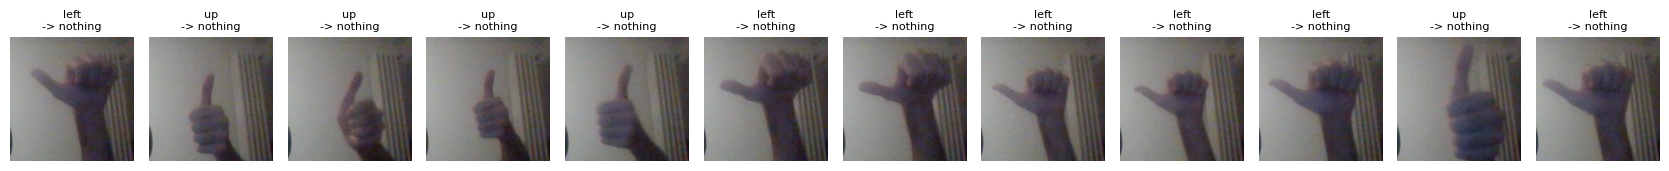

In [18]:
wrong = np.where(pred_va != y[va])[0]          # positions inside va
print(f"{len(wrong)} of {len(va)} validation crops wrong")
show = rng.choice(wrong, min(12, len(wrong)), replace=False) if len(wrong) else []
if len(show):
    fig, axes = plt.subplots(1, len(show), figsize=(1.4 * len(show), 1.9), squeeze=False)
    for ax, k in zip(axes[0], show):
        ax.imshow(X[va[k]][..., ::-1])
        ax.set_title(f"{CLASSES[y[va[k]]]}\n-> {CLASSES[pred_va[k]]}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

**On the instructor's recordings** 135 of the 250 validation crops are wrong, and the confusion
matrix shows they are not random: **every** "up" crop and **every** "left" crop of the validation
bursts is called "nothing", and 20 of the 50 "down" crops are called "right". Meanwhile all 50
"right" and all 50 "nothing" crops are right. The thumbs in the strip above are easy to read for
a human - so the network is reading something else. Part 4 finds out what.

## Part 3b - the same task without convolutions

Is the convolution doing anything? Try a **plain ANN** ([41]): flatten the crop into one long
vector and feed it to dense layers. To be fair it gets the same 64x64 crop as the CNN (after the same
2x2 averaging), so $64 \cdot 64 \cdot 3 = 12{,}288$ numbers go in.

What it lacks: every pixel has its own weights. A thumb that moves 5 pixels to the right lands on
different weights, so for the ANN it is a new input - nothing tells it that neighbouring pixels
belong together. A CNN slides one small filter over every position ([48]), so it finds a thumb
wherever it is.

In [19]:
def plain_ann():
    return nn.Sequential(
        nn.AvgPool2d(2),                  # (3, 128, 128) -> (3, 64, 64), as in the CNN
        nn.Flatten(),                     # -> 12,288 numbers: every pixel, every colour
        nn.Linear(3 * 64 * 64, 256),      # -> 256
        nn.ReLU(),
        nn.Linear(256, 128),              # -> 128
        nn.ReLU(),
        nn.Linear(128, len(CLASSES)),     # -> 5 class scores
    )


show_shapes(plain_ann())
n_ann = sum(p.numel() for p in plain_ann().parameters())
n_cnn = sum(p.numel() for p in small_cnn().parameters())
print(f"\nthe plain ANN has {n_ann / n_cnn:.0f}x the weights of the small CNN")

    layer        output shape       weights
    input        (3, 128, 128)   
 0  AvgPool2d    (3, 64, 64)              0
 1  Flatten      (12288,)                 0
 2  Linear       (256,)           3,145,984
 3  ReLU         (256,)                   0
 4  Linear       (128,)              32,896
 5  ReLU         (128,)                   0
 6  Linear       (5,)                   645
total weights: 3,179,525

the plain ANN has 72x the weights of the small CNN


Train it with the same loop, the same learning rate and the same batch order.

In [20]:
# ~20-30 s on 2 CPU threads (measured 17 s)
torch.manual_seed(SEED)
ann = plain_ann()
t0 = time.perf_counter()
hist_ann = train(ann, tr, va)
time_ann = time.perf_counter() - t0
acc_ann = hist_ann["val accuracy"].iloc[-1]
report("plain ANN", hist_ann, time_ann)

epoch  1/20 | loss: train 1.419, val 1.630 | accuracy: train  42.4%, val  20.0% |   1 s, ~15 s left


epoch  2/20 | loss: train 1.255, val 1.613 | accuracy: train  47.2%, val  20.8% |   2 s, ~14 s left


epoch  3/20 | loss: train 0.864, val 1.352 | accuracy: train  73.6%, val  48.8% |   2 s, ~13 s left


epoch  4/20 | loss: train 0.576, val 1.212 | accuracy: train  81.6%, val  49.6% |   3 s, ~13 s left


epoch  5/20 | loss: train 0.465, val 1.301 | accuracy: train  83.2%, val  37.6% |   4 s, ~12 s left


...

epoch 16/20 | loss: train 0.161, val 1.278 | accuracy: train  96.8%, val  33.2% |  14 s, ~3 s left


epoch 17/20 | loss: train 0.117, val 1.760 | accuracy: train  96.8%, val  45.6% |  15 s, ~3 s left


epoch 18/20 | loss: train 0.088, val 1.730 | accuracy: train  99.6%, val  49.6% |  16 s, ~2 s left


epoch 19/20 | loss: train 0.079, val 1.426 | accuracy: train  99.2%, val  40.8% |  16 s, ~1 s left


epoch 20/20 | loss: train 0.056, val 1.750 | accuracy: train  97.6%, val  49.6% |  17 s, ~0 s left
plain ANN: trained in 17 s | last epoch: train accuracy 97.6%, val accuracy 49.6% | best val accuracy 50.8% (epoch 9)


In [21]:
plot_history(hist_ann, "plain ANN (no convolutions)")

**On the instructor's recordings** the plain ANN ends at 49.6% (best 50.8%, epoch 9) - a little
*above* the small CNN's 46.0%, with 72x its weights. Do not cheer for it yet: the side-by-side
confusion matrices below show that it never answers "up" or "down" at all. Each of its 3 million
weights belongs to one pixel position, so it can learn "this exact pattern of pixels", not "a
thumb, wherever it is".

## Part 3c - a bigger CNN

What limits the small CNN? One suspect is how much of the crop a single neuron can see - its
**receptive field** ([48]). Every 3x3 conv widens it by 2 steps, every pool doubles the step. Count
it for every conv layer, in pixels of the 128 px crop:

In [22]:
def receptive_fields(model):
    # pixels of the input crop that one output position of each conv layer depends on
    r, step, out = 1, 1, []
    for i, layer in enumerate(model):
        if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.AvgPool2d)):
            k = layer.kernel_size if isinstance(layer.kernel_size, int) else layer.kernel_size[0]
            s = layer.stride if isinstance(layer.stride, int) else layer.stride[0]
            r += (k - 1) * step
            step *= s
            if isinstance(layer, nn.Conv2d):
                out.append(f"layer {i}: {r}x{r} px")
    return out


print("small CNN:", " | ".join(receptive_fields(small_cnn())))

small CNN: layer 1: 6x6 px | layer 5: 16x16 px | layer 9: 36x36 px


The last conv layer sees a 36x36 px patch of a 128 px crop - less than a hand. No single feature
sees the thumb *and* the fist it sticks out of.

The bigger CNN adds **two more conv blocks**, with 128 and 256 channels. The new channels sit where
the maps are already small (8x8 and 4x4), so they cost little time. Its head: the 2x2 maps flatten
to 1,024 numbers, then a hidden dense layer of 128, with **dropout** ([43]) before each dense
layer - while training, each number is zeroed with probability 0.5, so the net cannot lean on any
single feature. That is a brake on memorization.

In [23]:
def bigger_cnn():
    return nn.Sequential(
        nn.AvgPool2d(2),                      # (3, 128, 128) -> (3, 64, 64)

        nn.Conv2d(3, 16, 3, padding=1),       # block 1 -> (16, 64, 64)
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (16, 32, 32)

        nn.Conv2d(16, 32, 3, padding=1),      # block 2 -> (32, 32, 32)
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (32, 16, 16)

        nn.Conv2d(32, 64, 3, padding=1),      # block 3 -> (64, 16, 16)
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (64, 8, 8)

        nn.Conv2d(64, 128, 3, padding=1),     # block 4 (new) -> (128, 8, 8)
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (128, 4, 4)

        nn.Conv2d(128, 256, 3, padding=1),    # block 5 (new) -> (256, 4, 4)
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2),                      #         -> (256, 2, 2)

        nn.Flatten(),                         # -> 1,024 numbers
        nn.Dropout(0.5),                      # training only: zero each number with p = 0.5
        nn.Linear(256 * 2 * 2, 128),          # -> 128
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(128, len(CLASSES)),         # -> 5 class scores
    )

Its shapes, weights and receptive fields:

In [24]:
show_shapes(bigger_cnn())
print("\nbigger CNN:", " | ".join(receptive_fields(bigger_cnn())))

    layer        output shape       weights
    input        (3, 128, 128)   
 0  AvgPool2d    (3, 64, 64)              0
 1  Conv2d       (16, 64, 64)           448
 2  BatchNorm2d  (16, 64, 64)            32
 3  ReLU         (16, 64, 64)             0
 4  MaxPool2d    (16, 32, 32)             0
 5  Conv2d       (32, 32, 32)         4,640
 6  BatchNorm2d  (32, 32, 32)            64
 7  ReLU         (32, 32, 32)             0
 8  MaxPool2d    (32, 16, 16)             0
 9  Conv2d       (64, 16, 16)        18,496
10  BatchNorm2d  (64, 16, 16)           128
11  ReLU         (64, 16, 16)             0
12  MaxPool2d    (64, 8, 8)               0
13  Conv2d       (128, 8, 8)         73,856
14  BatchNorm2d  (128, 8, 8)            256
15  ReLU         (128, 8, 8)              0
16  MaxPool2d    (128, 4, 4)              0
17  Conv2d       (256, 4, 4)        295,168
18  BatchNorm2d  (256, 4, 4)            512
19  ReLU         (256, 4, 4)              0
20  MaxPool2d    (256, 2, 2)              

Train it - same loop, same data, same batch order.

In [25]:
# ~1-2 min on 2 CPU threads (measured 52 s)
torch.manual_seed(SEED)
big = bigger_cnn()
t0 = time.perf_counter()
hist_big = train(big, tr, va)
time_big = time.perf_counter() - t0
acc_big = hist_big["val accuracy"].iloc[-1]
report("bigger CNN", hist_big, time_big)

epoch  1/20 | loss: train 1.773, val 1.806 | accuracy: train  20.0%, val  20.0% |   2 s, ~33 s left


epoch  2/20 | loss: train 3.032, val 3.141 | accuracy: train  20.0%, val  20.0% |   3 s, ~30 s left


epoch  3/20 | loss: train 3.822, val 4.127 | accuracy: train  20.0%, val  20.0% |   5 s, ~27 s left


epoch  4/20 | loss: train 4.210, val 5.296 | accuracy: train  20.0%, val  20.0% |   7 s, ~26 s left


epoch  5/20 | loss: train 2.678, val 5.125 | accuracy: train  40.0%, val  20.0% |   9 s, ~26 s left


...

epoch 16/20 | loss: train 0.000, val 6.136 | accuracy: train 100.0%, val  40.0% |  41 s, ~10 s left


epoch 17/20 | loss: train 0.000, val 6.348 | accuracy: train 100.0%, val  40.0% |  44 s, ~8 s left


epoch 18/20 | loss: train 0.000, val 5.030 | accuracy: train 100.0%, val  40.0% |  47 s, ~5 s left


epoch 19/20 | loss: train 0.340, val 2.133 | accuracy: train  88.4%, val  51.6% |  49 s, ~3 s left


epoch 20/20 | loss: train 0.000, val 3.559 | accuracy: train 100.0%, val  42.0% |  52 s, ~0 s left
bigger CNN: trained in 52 s | last epoch: train accuracy 100.0%, val accuracy 42.0% | best val accuracy 51.6% (epoch 19)


In [26]:
plot_history(hist_big, "bigger CNN")

**On the instructor's recordings** bigger did not help: 42.0% after the last epoch (best 51.6%,
epoch 19), the lowest of the three. The curves show how. For four epochs it answers one class for
everything (20.0% on both sets) while the training loss climbs to 4.210; then it memorizes the
training burst in three epochs - 100.0% from epoch 7 - and the validation loss never comes back down
to where it started (1.806). Five blocks let it see the whole hand (156 px receptive field), and
dropout makes memorizing harder; neither helps when the training data itself rewards the wrong
clues.

(Training took 52 s here against the small CNN's 40 s. Part 8 times one frame through each
model - the cost that matters in the game.)

### The three networks side by side

Validation accuracy per epoch - the same measurement for all three, on one plot:

In [27]:
runs = {"plain ANN": (ann, hist_ann, time_ann, ARM_ORANGE),
        "small CNN": (cnn, hist_cnn, time_cnn, ARM_BLUE),
        "bigger CNN": (big, hist_big, time_big, ARM_RED)}
fig = go.Figure()
for name, (_, hist, _, color) in runs.items():
    fig.add_scatter(x=hist["epoch"], y=hist["val accuracy"], name=name, line_color=color)
fig.add_hline(y=1 / len(CLASSES), line_dash="dot", line_color="gray",
              annotation_text="guessing (20%)", annotation_position="bottom right")
fig.update_layout(height=340, xaxis_title="epoch", yaxis=dict(title="validation accuracy",
                  range=[0, 1.05], tickformat=".0%"), margin=dict(t=20))
fig.show()

The same comparison as a table:

In [28]:
rows = []
for name, (model, hist, seconds, _) in runs.items():
    best = hist.loc[hist["val accuracy"].idxmax()]
    rows.append({"model": name,
                 "weights": f"{sum(p.numel() for p in model.parameters()):,}",
                 "training time (s)": round(seconds),
                 "train accuracy, last epoch": f"{hist['train accuracy'].iloc[-1]:.1%}",
                 "val accuracy, last epoch": f"{hist['val accuracy'].iloc[-1]:.1%}",
                 "best val accuracy (epoch)": f"{best['val accuracy']:.1%} ({int(best['epoch'])})"})
pd.DataFrame(rows).set_index("model")

,weights,training time (s),"train accuracy, last epoch","val accuracy, last epoch",best val accuracy (epoch)
model,,,,,
plain ANN,"3,179,525",17,97.6%,49.6%,50.8% (9)
small CNN,"44,293",40,100.0%,46.0%,46.0% (10)
bigger CNN,"525,445",52,100.0%,42.0%,51.6% (19)


And which mistakes each one makes:

In [29]:
fig = make_subplots(rows=1, cols=3, subplot_titles=list(runs), horizontal_spacing=0.08)
for col, (name, (model, *_)) in enumerate(runs.items(), start=1):
    fig.add_trace(heatmap(confusion(predict(model, X[va]), y[va])), row=1, col=col)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title_text="predicted")
fig.update_yaxes(title_text="true", col=1)
fig.update_layout(height=360, width=1000, margin=dict(t=40))
fig.show()

**On the instructor's recordings** size and design hardly matter here: 49.6%, 46.0% and 42.0%
after the last epoch, and the order flips if you take each one's best epoch instead. The confusion
matrices are the real story. The three networks fail in the **same** places - "up" is right 0, 0
and 1 times out of 50 - and succeed in the same places: all 50 "right" crops, for every model.
When three different models make the same mistakes, suspect the data. Part 4 looks at it.

## Part 4 - error analysis: what is different between your bursts?

Three different networks, the same failures: each one gets its training crops (almost) all right,
and each one fails on the same validation classes. When different models make the **same**
mistakes, stop changing the model and look at the **data**.

For every class below: the training burst on top, the validation burst underneath. The first
picture of each row is the **average of all 50 frames**. The hand moves, so it blurs away; whatever
stays still - the background, the clothes - stays sharp.

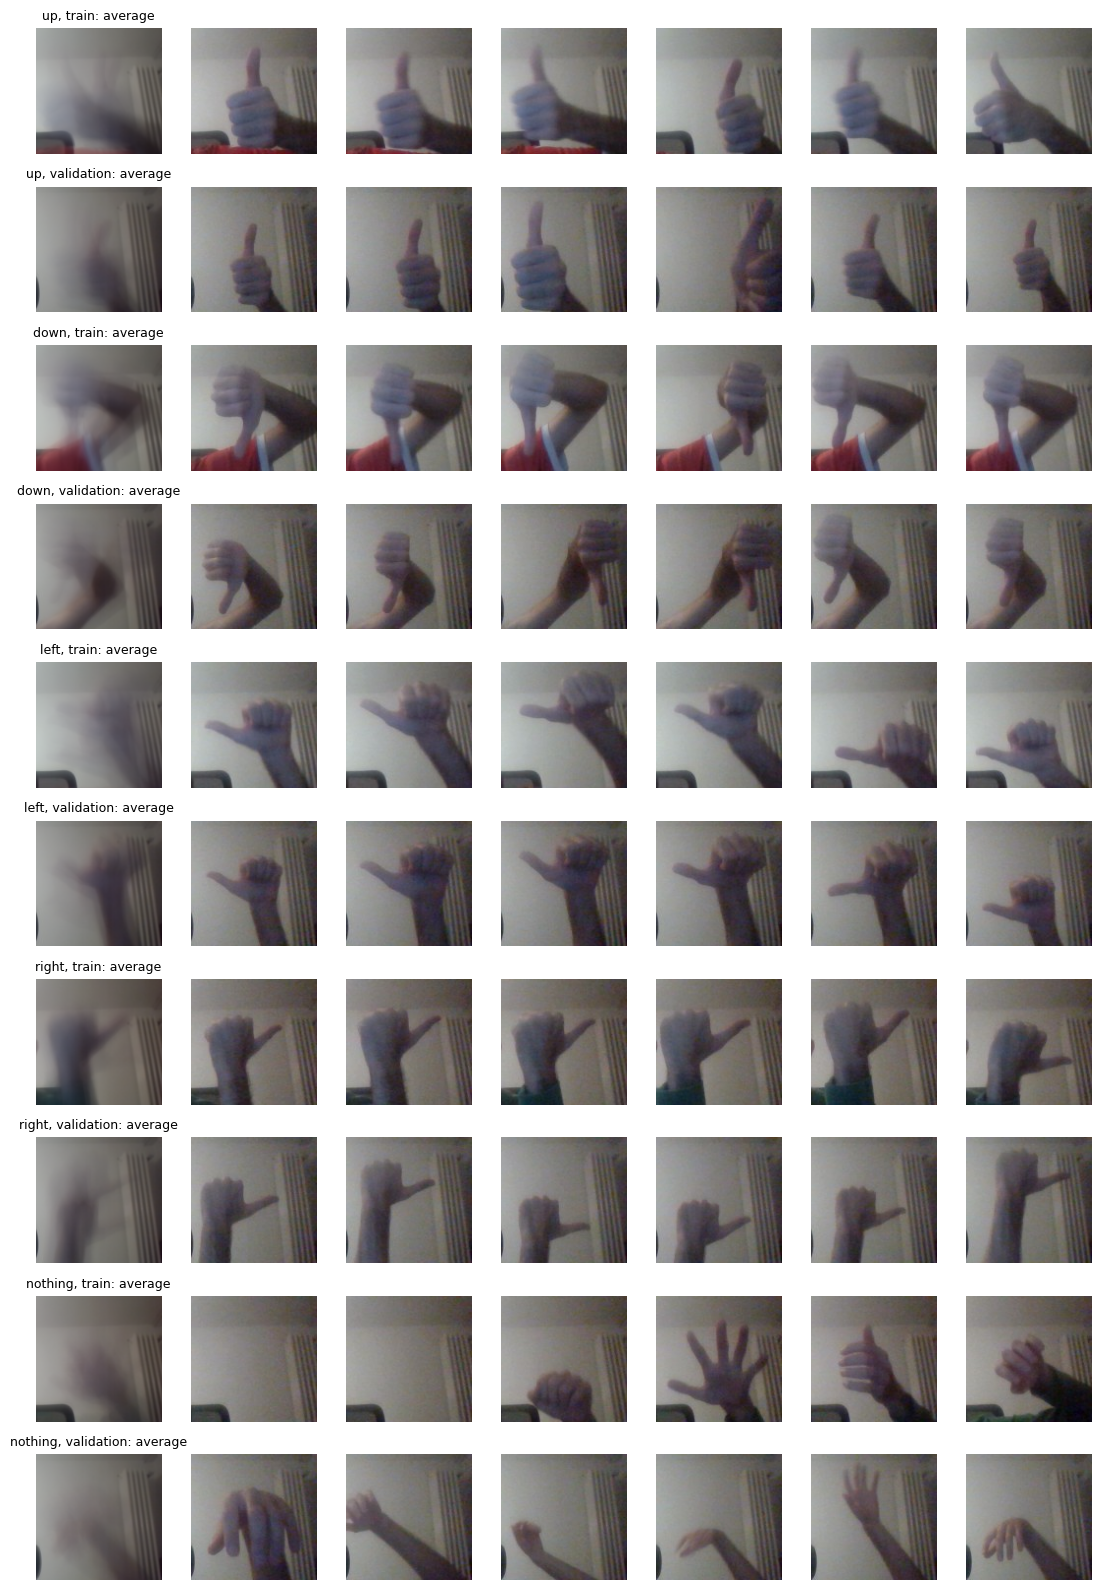

In [30]:
# ~3 s
fig, axes = plt.subplots(2 * len(CLASSES), 7, figsize=(11, 16))
for r, c in enumerate(CLASSES):
    for k, (name, idx) in enumerate([("train", tr), ("validation", va)]):
        frames = idx[y[idx] == r]
        row = axes[2 * r + k]
        row[0].imshow(X[frames].mean(0).astype(np.uint8)[..., ::-1])
        row[0].set_title(f"{c}, {name}: average", fontsize=9)
        for ax, i in zip(row[1:], frames[::9]):
            ax.imshow(X[i][..., ::-1])
        for ax in row:
            ax.axis("off")
plt.tight_layout()
plt.show()

**On the instructor's recordings** the differences were planted on purpose. Find them before you
read on:

- **sleeves** - a red sleeve only in the training "down" burst, a dark green one only in the
  training "right" burst; the validation bursts show bare forearms;
- **the corner** - the back of a dark chair sits in the bottom-left corner of the training "up",
  "left" and "nothing" bursts, and in no validation burst;
- **the radiator** - on the right edge of every training burst; for the validation bursts the box
  sat elsewhere, so the radiator is bigger and nearer the middle, and a dark object shows on the
  left edge;
- **"nothing"** - in training mostly an empty box, in validation mostly a hand or a forearm
  passing through.

None of these is the thumb, and every one of them is easier to see than the thumb.

**Can the background alone name the class?** If something other than the thumb separates the
training classes, a network can learn that instead - it has no idea which part of the picture you
care about. Test it with a classifier that never sees a hand: logistic regression ([11]) on just
**3 numbers**, the average blue, green and red of one region. The two small regions:

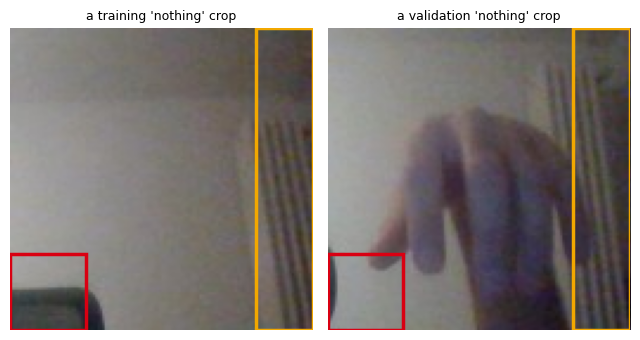

In [31]:
REGIONS = {"whole crop": (slice(0, 128), slice(0, 128)),
           "bottom-left corner": (slice(96, 128), slice(0, 32)),       # 32 x 32 px
           "right edge": (slice(0, 128), slice(104, 128))}             # 24 px wide

fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.4))
for ax, (title, i) in zip(axes, [("a training 'nothing' crop", tr[y[tr] == 4][0]),
                                 ("a validation 'nothing' crop", va[y[va] == 4][0])]):
    ax.imshow(X[i][..., ::-1])
    for name, color in [("bottom-left corner", ARM_RED), ("right edge", ARM_ORANGE)]:
        rows, cols = REGIONS[name]
        ax.add_patch(plt.Rectangle((cols.start - 0.5, rows.start - 0.5), cols.stop - cols.start,
                                   rows.stop - rows.start, fill=False, edgecolor=color, linewidth=2.5))
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rows = []
for name, (r_sl, c_sl) in REGIONS.items():
    colour = X[:, r_sl, c_sl].reshape(len(X), -1, 3).mean(1)       # 3 numbers per crop: mean B, G, R
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(colour[tr], y[tr])
    rows.append({"region": name, "train accuracy": clf.score(colour[tr], y[tr]),
                 "val accuracy": clf.score(colour[va], y[va])})
shortcuts = pd.DataFrame(rows).set_index("region")
print(shortcuts.map(lambda v: f"{v:.1%}"))

                   train accuracy val accuracy
region                                        
whole crop                  86.4%        30.4%
bottom-left corner          94.4%        22.0%
right edge                  76.8%        20.0%


In [33]:
fig = go.Figure()
for split, label, color in [("train", "train burst", ARM_BLUE), ("val", "validation burst", ARM_RED)]:
    vals = shortcuts[f"{split} accuracy"]
    fig.add_bar(x=[f"average colour of the<br>{r} (3 numbers)" for r in shortcuts.index], y=vals,
                name=label, marker_color=color, text=[f"{v:.1%}" for v in vals], textposition="outside")
fig.add_hline(y=1 / len(CLASSES), line_dash="dot", line_color="gray",
              annotation_text="guessing (20%)", annotation_position="top right")
fig.update_layout(height=380, width=700, barmode="group", margin=dict(t=20),
                  yaxis=dict(range=[0, 1.1], title="accuracy", tickformat=".0%"))
fig.show()

**On the instructor's recordings** three numbers are enough. The average colour of the
bottom-left corner - 32x32 px of wall and chair, where the hand rarely goes - names the training
class **94.4%** of the time. On the validation bursts the same classifier gets 22.0%: chance. The
right edge, where the radiator is, does the same (76.8% against 20.0%), and so does the colour of
the whole crop (86.4% against 30.4%).

That is the trap in one table. On the training bursts the background **is** a reliable clue - more
reliable, and much easier to see, than a thumb. A network that only tries to get its training crops
right has every reason to use it, and nothing in the loss tells it that the corner is cheating.
This is [50]'s Clever Hans, at home.

**Which training crop does each validation crop look like?** For every validation crop, find the
single most similar training crop in raw pixels (both shrunk to 32x32 and compared pixel by pixel),
and count the class of that nearest training crop:

In [34]:
pix = F.avg_pool2d(bgr_to_tensor(X), 4).flatten(1).numpy()     # 32 x 32 x 3 = 3,072 numbers per crop
# squared distance between every validation crop and every training crop: |a|^2 + |b|^2 - 2 a.b
dist = (pix[va] ** 2).sum(1)[:, None] + (pix[tr] ** 2).sum(1)[None, :] - 2 * pix[va] @ pix[tr].T
nearest = tr[dist.argmin(1)]                                    # one training index per validation crop
confusion(y[nearest], y[va]).rename_axis(index="validation crop", columns="its nearest training crop")

its nearest training crop,up,down,left,right,nothing
validation crop,,,,,
up,3,0,0,2,45
down,0,12,0,19,19
left,0,0,0,0,50
right,0,0,0,47,3
nothing,3,0,1,0,46


One validation crop per class (top) and its nearest training crop (bottom):

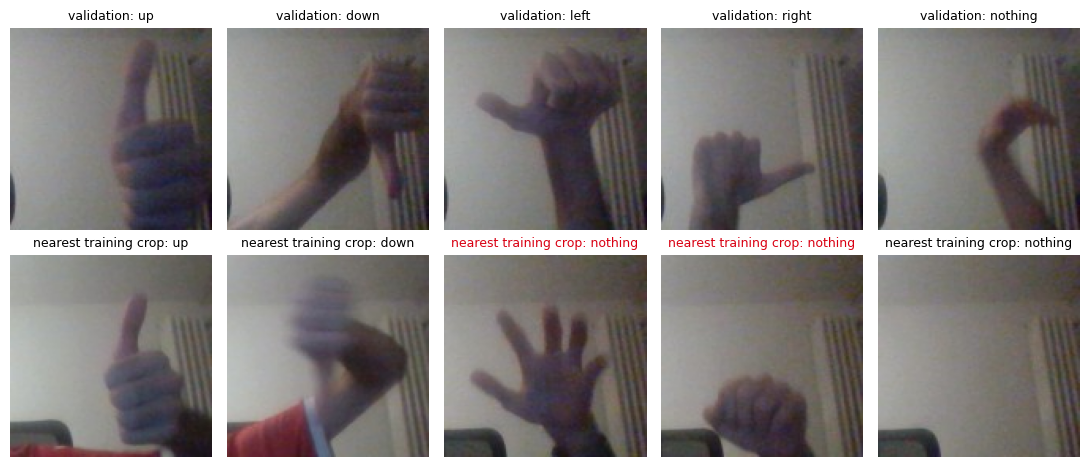

In [35]:
fig, axes = plt.subplots(2, len(CLASSES), figsize=(11, 4.8))
for c_idx, c in enumerate(CLASSES):
    k = np.where(y[va] == c_idx)[0][25]                         # the middle of the burst
    j = nearest[k]
    axes[0, c_idx].imshow(X[va[k]][..., ::-1])
    axes[0, c_idx].set_title(f"validation: {c}", fontsize=9)
    axes[1, c_idx].imshow(X[j][..., ::-1])
    axes[1, c_idx].set_title(f"nearest training crop: {CLASSES[y[j]]}", fontsize=9,
                             color="black" if y[j] == c_idx else ARM_RED)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

**On the instructor's recordings** this table is almost the small CNN's confusion matrix from
Part 3. In raw pixels, 45 of the 50 validation "up" crops and all 50 "left" crops are closest to a
crop of the training "nothing" burst - and the small CNN called every "up" and every "left" crop
"nothing". The background fills most of the crop, so whole-picture similarity follows the
background. The network learned pictures, not thumbs. (The pairs above show the pattern and one
exception: this "up" crop does find a training "up".)

**What would fix it?** Better data, not a bigger network: more bursts per class, and between them
change everything that should **not** matter - sleeves, light, where you sit, which side the box is
on, what is behind you. Then the only thing that stays the same within a class is the thumb, and the
easiest way to get the training crops right is to look at it. Part 6 tries a cheap substitute.

## Part 5 - Grad-CAM: is it looking at your thumb?

Part 4 found clues in the data that are not the thumb. Grad-CAM ([50]) shows where a network
actually looks when it decides - so you can check whether it uses them. Its three steps, as in
[50]:

1. take the feature maps of the **last conv block** (before its pool);
2. weight each map by the **average gradient** of the predicted class score with respect to it;
3. sum, ReLU, upsample to the crop size.

In [36]:
def gradcam(model, img, layer):
    # img: one BGR crop. Returns (heatmap in [0, 1] of the crop's size, predicted class index)
    store = {}
    hook = layer.register_forward_hook(lambda m, inp, out: store.__setitem__("A", out))
    model.eval()
    try:
        logits = model(bgr_to_tensor(img))
    finally:
        hook.remove()
    k = int(logits.argmax())
    A = store["A"]                                           # (1, maps, h, w)
    grad, = torch.autograd.grad(logits[0, k], A)             # same shape as A
    weights = grad.mean(dim=(2, 3), keepdim=True)            # step 2: one weight per map
    cam = F.relu((weights * A).sum(1, keepdim=True))         # step 3: weighted sum, ReLU
    cam = F.interpolate(cam, size=img.shape[:2], mode="bilinear")[0, 0].detach()
    return (cam / (cam.max() + 1e-8)).numpy(), k

The layer to watch is the **ReLU of the last conv block** - layer 11 of the small CNN (64 maps of
16x16) and layer 19 of the bigger one (256 maps of only 4x4, so its heatmaps come out blurrier).
The `show_shapes` printouts above have the numbers.

In [37]:
cam_layers = {"small CNN": (cnn, cnn[11]), "bigger CNN": (big, big[19])}
for name, (model, layer) in cam_layers.items():
    assert isinstance(layer, nn.ReLU), f"{name}: expected the last conv block's ReLU, got {layer}"
    print(name, "->", layer)

small CNN -> ReLU()
bigger CNN -> ReLU()


Two held-out crops per class. Each crop appears twice: with the small CNN's heatmap, and with the
bigger CNN's. Red = the evidence the prediction rests on; a red title = a wrong prediction.

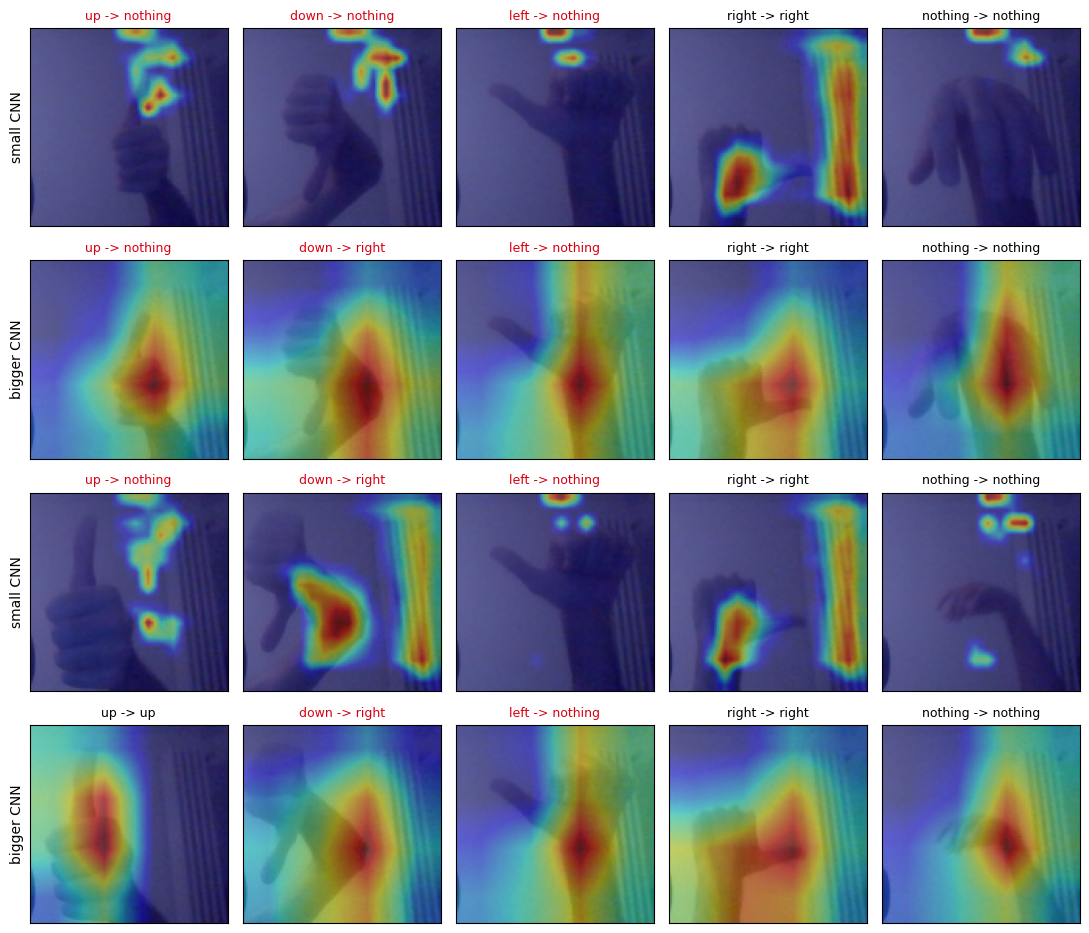

In [38]:
# ~5 s
fig, axes = plt.subplots(4, len(CLASSES), figsize=(11, 9.5))
for c_idx, c in enumerate(CLASSES):
    for pair, i in enumerate(rng.choice(va[y[va] == c_idx], 2, replace=False)):
        for m, (name, (model, layer)) in enumerate(cam_layers.items()):
            cam, k = gradcam(model, X[i], layer)
            ax = axes[2 * pair + m, c_idx]
            ax.imshow(X[i][..., ::-1])
            ax.imshow(cam, cmap="jet", alpha=0.45)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(f"{c} -> {CLASSES[k]}", fontsize=9, color="black" if k == c_idx else ARM_RED)
            if c_idx == 0:
                ax.set_ylabel(name, fontsize=10)
plt.tight_layout()
plt.show()

**On the instructor's recordings** the small CNN's heat on its failures sits on the **radiator**
and the top edge of the box, not on the hand: "up -> nothing", "down -> nothing" and
"left -> nothing" all point at the stripes on the right. Even its correct "right" answers use the
radiator strip next to the fist. That is Part 4's finding seen from inside the network: it reads
the part of the picture that changed between the two recording sessions.

The bigger CNN's heat is one blob in the middle of every crop, which tells us little: its last conv
layer has only 4x4 positions to point at. Coarse final maps are a real limit of Grad-CAM.

## Part 6 - augmentation, as an experiment

Part 4's real fix is more, and more varied, data. The cheap substitute is **augmentation** ([43]):
train on changed copies of the training crops, so that whatever the change touches stops being
something the network can rely on. Three changes, then the bigger CNN trained again with them.

**Mirroring, with a twist.** In [43] a mirrored cat is still a cat. Here a mirrored **left** thumb
is a **right** thumb: the mirror is still free extra data, but the label has to flip with it.
`FLIP[k]` is the class that class `k` becomes in the mirror.

In [39]:
FLIP = torch.tensor([CLASSES.index({"left": "right", "right": "left"}.get(c, c)) for c in CLASSES])
print({c: CLASSES[int(j)] for c, j in zip(CLASSES, FLIP)})


def mirror_batch(xb, yb):
    # mirror every image left-right, and give each one the label it has in the mirror
    return xb.flip(3), FLIP[yb]

{'up': 'up', 'down': 'down', 'left': 'right', 'right': 'left', 'nothing': 'nothing'}


Check it on one `left` crop: the mirrored picture must be labelled `right`, and mirroring twice
must give back the original.

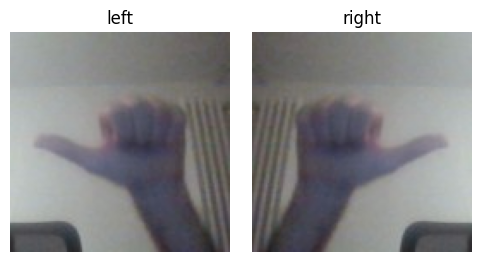

In [40]:
i_left = np.where(y == CLASSES.index("left"))[0][0]
x1, y1 = bgr_to_tensor(X[i_left]), torch.tensor([y[i_left]])
xm, ym = mirror_batch(x1, y1)
assert CLASSES[int(ym)] == "right" and torch.equal(xm, x1.flip(3))
assert torch.equal(mirror_batch(xm, ym)[0], x1) and int(mirror_batch(xm, ym)[1]) == int(y1)
fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
for ax, img, lab in [(axes[0], x1, y1), (axes[1], xm, ym)]:
    ax.imshow(img[0].permute(1, 2, 0))
    ax.set_title(CLASSES[int(lab)])
    ax.axis("off")
plt.tight_layout()
plt.show()

The full augmentation, in three steps: mirror half the batch (and swap the labels), change
brightness and contrast (your room at 9 am is not your room at 9 pm), and shift each crop by up to
8 pixels (your hand is never in exactly the same spot).

In [41]:
def augment(xb, yb, pad=8):
    # xb: (B, 3, H, W) in [0, 1], yb: (B,) class indices
    B, _, H, W = xb.shape

    # 1. mirror a random half of the batch - and swap left / right in their labels
    flip = torch.rand(B) < 0.5
    xm, ym = mirror_batch(xb, yb)
    xb = torch.where(flip[:, None, None, None], xm, xb)
    yb = torch.where(flip, ym, yb)

    # 2. contrast and brightness: x * gain + bias, a different pair for every image
    gain = torch.empty(B, 1, 1, 1).uniform_(0.7, 1.3)
    bias = torch.empty(B, 1, 1, 1).uniform_(-0.1, 0.1)
    xb = (xb * gain + bias).clamp(0, 1)

    # 3. shift: pad 8 px on every side, then cut an H x W window at a random offset
    padded = F.pad(xb, (pad, pad, pad, pad), mode="replicate")
    offsets = torch.randint(0, 2 * pad + 1, (B, 2)).tolist()
    xb = torch.stack([padded[k, :, i:i + H, j:j + W] for k, (i, j) in enumerate(offsets)])
    return xb, yb

What the network sees during training from now on: one crop and eight random augmentations of it.
Watch the label whenever the picture is mirrored.

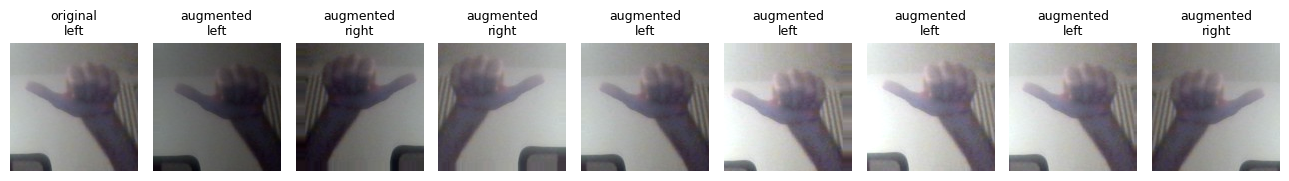

In [42]:
torch.manual_seed(SEED)
i0 = np.where(y == CLASSES.index("left"))[0][10]
copies = bgr_to_tensor(X[i0]).repeat(8, 1, 1, 1)                 # 8 copies of the same crop
xa, ya = augment(copies, torch.full((8,), int(y[i0])))
fig, axes = plt.subplots(1, 9, figsize=(13, 1.9))
axes[0].imshow(X[i0][..., ::-1])
axes[0].set_title(f"original\n{CLASSES[y[i0]]}", fontsize=9)
for ax, img, lab in zip(axes[1:], xa, ya):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(f"augmented\n{CLASSES[int(lab)]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Now the bigger CNN again: same architecture, same seed, same batch order, same 20 epochs - the
only change is `augment=augment`. Every epoch now sees freshly changed copies.

In [43]:
# ~1-2 min on 2 CPU threads (measured 59 s)
torch.manual_seed(SEED)
big_aug = bigger_cnn()
t0 = time.perf_counter()
hist_aug = train(big_aug, tr, va, augment=augment)
time_aug = time.perf_counter() - t0
acc_aug = hist_aug["val accuracy"].iloc[-1]
report("bigger CNN + augmentation", hist_aug, time_aug)

epoch  1/20 | loss: train 1.595, val 1.609 | accuracy: train  20.0%, val  20.0% |   4 s, ~70 s left


epoch  2/20 | loss: train 1.828, val 1.867 | accuracy: train  20.0%, val  20.0% |   7 s, ~64 s left


epoch  3/20 | loss: train 1.324, val 1.573 | accuracy: train  52.0%, val  30.0% |  10 s, ~58 s left


epoch  4/20 | loss: train 0.584, val 0.973 | accuracy: train  76.4%, val  56.0% |  14 s, ~55 s left


epoch  5/20 | loss: train 0.690, val 1.023 | accuracy: train  75.2%, val  59.2% |  16 s, ~47 s left


...

epoch 16/20 | loss: train 0.018, val 2.734 | accuracy: train 100.0%, val  49.2% |  50 s, ~13 s left


epoch 17/20 | loss: train 0.020, val 0.426 | accuracy: train  99.6%, val  87.2% |  52 s, ~9 s left


epoch 18/20 | loss: train 0.122, val 0.864 | accuracy: train  95.2%, val  76.4% |  54 s, ~6 s left


epoch 19/20 | loss: train 0.002, val 0.830 | accuracy: train 100.0%, val  76.4% |  57 s, ~3 s left


epoch 20/20 | loss: train 0.001, val 1.329 | accuracy: train 100.0%, val  66.0% |  59 s, ~0 s left
bigger CNN + augmentation: trained in 59 s | last epoch: train accuracy 100.0%, val accuracy 66.0% | best val accuracy 90.0% (epoch 9)


In [44]:
plot_history(hist_aug, "bigger CNN + augmentation")

Without and with augmentation, side by side - validation accuracy per epoch, and the confusion
matrices after the last epoch:

In [45]:
fig = make_subplots(rows=1, cols=3, column_widths=[0.4, 0.3, 0.3], horizontal_spacing=0.08,
                    subplot_titles=("validation accuracy", "without augmentation", "with augmentation"))
for hist, name, color in [(hist_big, "without", ARM_BLUE), (hist_aug, "with augmentation", ARM_RED)]:
    fig.add_scatter(x=hist["epoch"], y=hist["val accuracy"], name=name, line_color=color, row=1, col=1)
fig.add_trace(heatmap(confusion(predict(big, X[va]), y[va])), row=1, col=2)
fig.add_trace(heatmap(confusion(predict(big_aug, X[va]), y[va])), row=1, col=3)
fig.update_yaxes(range=[0, 1.05], tickformat=".0%", row=1, col=1)
fig.update_yaxes(autorange="reversed", row=1, col=2)
fig.update_yaxes(autorange="reversed", row=1, col=3)
fig.update_xaxes(title_text="epoch", row=1, col=1)
fig.update_layout(height=380, width=1050, margin=dict(t=40), legend=dict(x=0, y=-0.25, orientation="h"))
fig.show()

**On the instructor's recordings** augmentation turns the bigger CNN from the worst network into
the best: 66.0% after the last epoch instead of 42.0%, and 90.0% at its best epoch (9). The
confusion matrices show where the gain comes from: "down" goes from 4 to 33 right, "left" from 0
to 34, "up" from 1 to 8, while "right" and "nothing" give a few back (50 -> 44, 50 -> 46).

Why it helps here:

- brightness and contrast changes make **colour** a less reliable clue - and Part 4 showed that
  colour alone named the training class;
- shifts move the corner and the edge around, so a fixed spot of the background stops being a
  fixed clue;
- the mirror shows every "left" thumb also as a "right" one, **in the same room** - so the room
  stops predicting the direction.

The price is jumpiness: the validation curve swings between 31.6% and 90.0%. And "up" is still
mostly called "nothing": augmentation made the shortcuts less worth learning, it did not remove
them. Try it on the small CNN yourself - one argument, `augment=augment`.

## Part 7 - the random-split trap, measured

Take a model with **no understanding at all**: 1-nearest-neighbour on raw pixels (the classic
methods chapter). It answers with the label of the single most similar training crop - pure
memory - the nearest-neighbour search of Part 4. Score it twice: validation frames drawn **at
random** (every one has near-copies in training), and the burst split from Part 2.

In [46]:
# ~7 s
from sklearn.neighbors import KNeighborsClassifier

perm = rng.permutation(len(y))                  # pix: the 32 x 32 pixels from Part 4
va_rand, tr_rand = perm[:len(va)], perm[len(va):]


def knn_accuracy(tr_idx, va_idx):
    knn = KNeighborsClassifier(n_neighbors=1).fit(pix[tr_idx], y[tr_idx])
    return knn.score(pix[va_idx], y[va_idx])


acc_knn_rand = knn_accuracy(tr_rand, va_rand)
acc_knn_burst = knn_accuracy(tr, va)
print(f"1-NN on pixels: random split {acc_knn_rand:.1%} | burst split {acc_knn_burst:.1%}")

1-NN on pixels: random split 100.0% | burst split 43.2%


Next to the networks (all on the burst split):

In [47]:
names = ["1-NN, random split", "1-NN, burst split", "plain ANN", "small CNN", "bigger CNN",
         "bigger CNN<br>+ augmentation"]
vals = [acc_knn_rand, acc_knn_burst, acc_ann, acc_cnn, acc_big, acc_aug]
colors = [ARM_RED, ARM_ORANGE, ARM_BLUE, ARM_BLUE, ARM_BLUE, ARM_BLUE]
fig = go.Figure(go.Bar(x=names, y=vals, marker_color=colors,
                       text=[f"{v:.1%}" for v in vals], textposition="outside"))
fig.update_layout(height=360, width=720, yaxis=dict(range=[0, 1.1], title="validation accuracy",
                  tickformat=".0%"), margin=dict(t=20))
fig.show()

**On the instructor's recordings** pure memory scores 100.0% on the random split and 43.2% on the
burst split. A random split would have reported a perfect model; the burst split shows what is left
once the near-copies are gone. Without augmentation the networks barely beat memory (49.6%, 46.0%)
or fall below it (the bigger CNN, 42.0%); with augmentation the bigger CNN reaches 66.0%.

## Part 8 - transfer learning: frozen ResNet-18 features

All three networks above learned to see from **250 crops**. ResNet-18 ([49]) learned to see from
**1.28 million** ImageNet photos in 1,000 classes. [50]'s Recipe 1 borrows that: keep everything
ResNet-18 learned, throw away only its last layer, and train a small classifier on top.

```
your crop         ImageNet           ResNet-18 trunk         512           logistic         5 class
(3, 128, 128) --> normalization -->  FROZEN, ~11 million -> numbers  -->  regression  -->  scores
                                     weights, no training                  (trained)
```

Step by step: load the model, see what it thinks of your crops as it is, cut off its head, look
inside, then compute features and fit the classifier.

**Load it.** The weights download once (47 MB) and are cached after that.

In [48]:
# ~2 s, plus a one-time 47 MB download of the ResNet-18 weights on the first run
from torchvision.models import ResNet18_Weights, resnet18

weights = ResNet18_Weights.IMAGENET1K_V1
trunk = resnet18(weights=weights)
trunk.eval()          # BatchNorm uses its stored ImageNet statistics - never the batch's ([50])
IMAGENET_CLASSES = weights.meta["categories"]
print(f"ResNet-18: {sum(p.numel() for p in trunk.parameters()):,} weights, "
      f"{len(IMAGENET_CLASSES)} ImageNet classes, e.g. {IMAGENET_CLASSES[:3]}")

ResNet-18: 11,689,512 weights, 1000 ImageNet classes, e.g. ['tench', 'goldfish', 'great white shark']


**Normalize like ImageNet.** ResNet-18 was trained on images with each colour channel shifted and
scaled by ImageNet's mean and standard deviation. It must get its inputs the same way - ImageNet's
numbers, not ours.

In [49]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)    # R, G, B
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def to_resnet(xb):
    # (N, 3, H, W) RGB in [0, 1] -> what ResNet-18 was trained on
    return (xb - MEAN) / STD

**What does it see, as it is?** The untouched ResNet-18 can only answer with one of its 1,000
ImageNet classes. None of them is "thumb up". Its top three guesses for one crop per class:

      up: plunger 77% | electric guitar 11% | acoustic guitar 3%
    down: basketball 13% | hand blower 13% | punching bag 12%


    left: cello 48% | hand blower 16% | harp 7%
   right: hammerhead 87% | hammer 3% | gar 1%
 nothing: African grey 90% | toucan 2% | vulture 2%


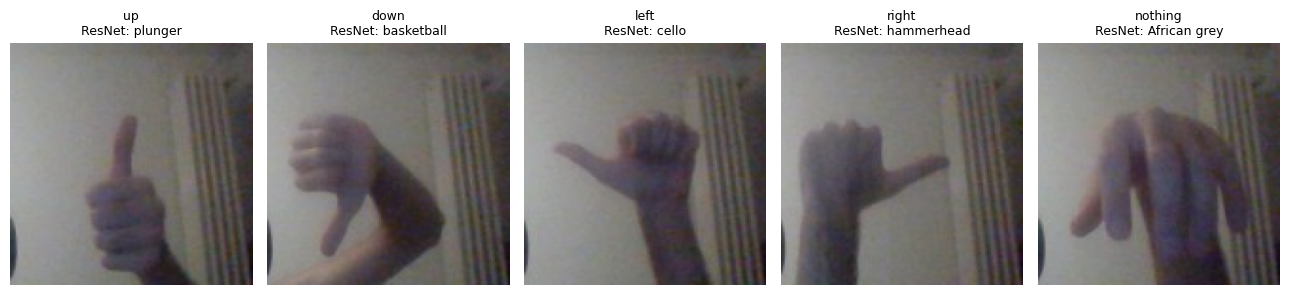

In [50]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(13, 3.2))
for ax, c_idx in zip(axes, range(len(CLASSES))):
    i = va[y[va] == c_idx][0]
    with torch.no_grad():
        probs = torch.softmax(trunk(to_resnet(bgr_to_tensor(X[i]))), dim=1)[0]
    top = probs.topk(3)
    guesses = [f"{IMAGENET_CLASSES[int(j)]} {float(p):.0%}" for p, j in zip(top.values, top.indices)]
    print(f"{CLASSES[c_idx]:>8}: " + " | ".join(guesses))
    ax.imshow(X[i][..., ::-1])
    ax.set_title(f"{CLASSES[c_idx]}\nResNet: {IMAGENET_CLASSES[int(top.indices[0])]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**On the instructor's recordings:** plunger, basketball, cello, hammerhead (the shark), African
grey (the parrot) - with up to 90% confidence, and all meaningless, because "thumb" is not one of its
1,000 classes. Its last layer is useless to us. The layers *before* it are what we want: they
learned edges, textures, shapes and parts - what every one of those 1,000 classes is made of.

**Cut off the head.** The last layer, `fc`, turns 512 features into 1,000 ImageNet scores. Replace
it with `nn.Identity()` - a layer that returns its input unchanged - and the network outputs the
512 features themselves. Then freeze every weight: nothing in the trunk will be trained.

In [51]:
print("before:", trunk.fc)
trunk.fc = nn.Identity()
print("after: ", trunk.fc)
for p in trunk.parameters():
    p.requires_grad = False
n_trainable = sum(p.numel() for p in trunk.parameters() if p.requires_grad)
print(f"trainable weights left in the trunk: {n_trainable}")

before: Linear(in_features=512, out_features=1000, bias=True)
after:  Identity()
trainable weights left in the trunk: 0


**Look inside.** ResNet-18 is a stem (one big conv and a pool) followed by four stages of residual
blocks ([49]), then a global average pool. Follow one crop through it:

In [52]:
x = to_resnet(torch.zeros(1, 3, CROP_SIZE, CROP_SIZE))
print(f"{'stage':<10} {'output shape':<18} {'weights':>11}")
print(f"{'input':<10} {str(tuple(x.shape[1:])):<18}")
with torch.no_grad():
    for name, stage in trunk.named_children():
        if name == "fc":
            x = torch.flatten(x, 1)               # ResNet's forward() flattens before fc
        x = stage(x)
        n = sum(p.numel() for p in stage.parameters())
        print(f"{name:<10} {str(tuple(x.shape[1:])):<18} {n:>11,}")

stage      output shape           weights
input      (3, 128, 128)     
conv1      (64, 64, 64)             9,408
bn1        (64, 64, 64)               128
relu       (64, 64, 64)                 0
maxpool    (64, 32, 32)                 0
layer1     (64, 32, 32)           147,968
layer2     (128, 16, 16)          525,568
layer3     (256, 8, 8)          2,099,712
layer4     (512, 4, 4)          8,393,728
avgpool    (512, 1, 1)                  0
fc         (512,)                       0


Note the shapes: our 128 px crop ends as **4x4** maps in `layer4` - ResNet-18 was built for
224 px photos (7x7 there), but convolutions work at any size. `avgpool` then averages each of the
512 maps to one number.

**Features, once.** The trunk never changes, so every crop's 512 features are computed one time,
not once per epoch.

In [53]:
def features(imgs, bs=128):
    # 512 ResNet-18 features per BGR crop
    out = []
    with torch.no_grad():
        for s in range(0, len(imgs), bs):
            xb = bgr_to_tensor(imgs[s:s + bs])
            out.append(trunk(to_resnet(xb)))
    return torch.cat(out).numpy()

In [54]:
# ~10 s for 500 crops on 2 CPU threads (measured 9 s)
t0 = time.perf_counter()
F_tr = features(X[tr])
F_va = features(X[va])
print(f"training features {F_tr.shape}, validation features {F_va.shape}, "
      f"in {time.perf_counter() - t0:.0f} s")

training features (250, 512), validation features (250, 512), in 9 s


**Do the features already separate the classes?** Squash each crop to 2 numbers with PCA and colour
it by class: left, the raw pixels; right, the 512 ResNet-18 features. Circles are training crops,
crosses validation crops.

In [55]:
from sklearn.decomposition import PCA

CLASS_COLORS = {"up": ARM_BLUE, "down": ARM_RED, "left": ARM_ORANGE, "right": "#2E8B57", "nothing": "#888888"}
views = {"raw pixels": (pix[tr], pix[va]), "ResNet-18 features": (F_tr, F_va)}
fig = make_subplots(rows=1, cols=2, subplot_titles=list(views))
for col, (title, (A_tr, A_va)) in enumerate(views.items(), start=1):
    pca = PCA(n_components=2).fit(A_tr)
    for split, A, idx, symbol in [("train", A_tr, tr, "circle"), ("val", A_va, va, "x")]:
        P = pca.transform(A)
        for c_idx, c in enumerate(CLASSES):
            m = y[idx] == c_idx
            fig.add_scatter(x=P[m, 0], y=P[m, 1], mode="markers", name=f"{c} ({split})",
                            marker=dict(color=CLASS_COLORS[c], symbol=symbol, size=6, opacity=0.7),
                            legendgroup=c, showlegend=(col == 1), row=1, col=col)
fig.update_xaxes(title_text="PCA 1")
fig.update_yaxes(title_text="PCA 2")
fig.update_layout(height=420, margin=dict(t=40))
fig.show()

**On the instructor's recordings.** Raw pixels: each training burst (circles) is its own tight
curve, and the validation crops (crosses) of the same class land somewhere else - the pixels mostly
tell *bursts* apart, not classes. In the ResNet-18 features training and validation crops share
the same region much more, but in 2 dimensions the classes still overlap; only the training "down"
burst stands apart. Two dimensions out of 512 is a heavy squash - the classifier below gets all 512.

**The classifier.** Logistic regression ([11]) on the 512 features: one weight per feature and
class, $512 \cdot 5 + 5 = 2{,}565$ numbers to learn - instead of the trunk's 11 million. `C=0.5`
is the inverse regularization strength (smaller = stronger), `max_iter` just lets the solver
finish.

In [56]:
from sklearn.linear_model import LogisticRegression

probe = LogisticRegression(max_iter=3000, C=0.5).fit(F_tr, y[tr])
train_acc_probe = (probe.predict(F_tr) == y[tr]).mean()
acc_probe = (probe.predict(F_va) == y[va]).mean()
print(f"ResNet-18 + logistic regression: train accuracy {train_acc_probe:.1%}, "
      f"val accuracy {acc_probe:.1%}")
print(f"for comparison, val accuracy after the last epoch: plain ANN {acc_ann:.1%}, "
      f"small CNN {acc_cnn:.1%}, bigger CNN {acc_big:.1%}, bigger CNN + augmentation {acc_aug:.1%}")

ResNet-18 + logistic regression: train accuracy 100.0%, val accuracy 64.0%
for comparison, val accuracy after the last epoch: plain ANN 49.6%, small CNN 46.0%, bigger CNN 42.0%, bigger CNN + augmentation 66.0%


Its confusion matrix on the held-out bursts:

In [57]:
fig = go.Figure(heatmap(confusion(probe.predict(F_va), y[va])))
fig.update_layout(height=360, width=420, xaxis_title="predicted", yaxis_title="true",
                  yaxis_autorange="reversed", margin=dict(t=20))
fig.show()

**On the instructor's recordings** the frozen ResNet-18 reaches 64.0% - far above the three
networks trained from scratch without augmentation (49.6%, 46.0%, 42.0%), and close to the
augmented bigger CNN (66.0%) without any augmentation of its own. Like them it gets every training
crop right (100.0%). Unlike them it does not depend on a lucky epoch - logistic regression has a
single answer - and it learned only 2,565 numbers from your crops. Its mistakes: 31 of the 50 "up"
crops go to "nothing", and 18 of the 50 "left" crops to "right".

Accuracy is not the only cost in a game: every frame has to be classified before the next one
arrives. Time one crop through each model:

In [58]:
# ~5 s
x1 = bgr_to_tensor(X[va[:1]])


def ms_per_frame(f, reps=30):
    with torch.no_grad():
        f(x1)                                   # warm-up
        t0 = time.perf_counter()
        for _ in range(reps):
            f(x1)
    return (time.perf_counter() - t0) / reps * 1e3


for model in (ann, cnn, big):
    model.eval()
timings = {"plain ANN": ann, "small CNN": cnn, "bigger CNN": big,
           "ResNet-18": lambda x: trunk(to_resnet(x))}
for name, f in timings.items():
    print(f"{name:<11} {ms_per_frame(f):6.1f} ms per frame")

plain ANN      1.7 ms per frame


small CNN      5.1 ms per frame


bigger CNN     8.3 ms per frame


ResNet-18     59.6 ms per frame


**On the instructor's laptop** the networks trained here need 1.7 to 8.3 ms per frame; ResNet-18
needs 59.6 ms - longer than the 33 ms between two frames of a 30 fps webcam, so with it the game
runs at a lower frame rate. (Timings change from run to run.)

## Part 8b - fine-tuning: retrain the last conv layer

Part 8 was [50]'s **Recipe 1**: all of ResNet-18's 11 million weights frozen, only a logistic
regression trained on top. Its 512 features were shaped for ImageNet's sharks and parrots, and
they never learn anything about thumbs.

[50]'s **Recipe 2 - fine-tuning** lets part of the trunk adapt. Which part? The early layers find
edges and textures that every photo has; the last ones combine them into ImageNet's classes. So
unfreeze the top and keep the rest. With 250 training crops we unfreeze as little as possible:
the **last conv layer** alone.

```
your crop -> ImageNet      -> stem, layer1-3, layer4[0]  -> last conv layer  -> average -> head      -> 5 class
             normalization    and the first conv of         layer4[1].conv2     pool       512 -> 5     scores
                              layer4[1]: FROZEN             TRAINED                        TRAINED, starts
                                                                                           as Part 8's probe
```

Three rules from [50], each one a line of code below:

1. **Linear probe first, then fine-tune (LP-FT).** The head starts as Part 8's logistic regression,
   not random. A random head has learned nothing yet, so the first gradients it sends into the conv
   layer point in meaningless directions - and bend the features anyway. (We test this one: the
   second run below skips it.)
2. **A modest learning rate**: 1e-3, half of the 2e-3 we used from scratch. The weights start near a
   good minimum; we nudge them, we do not start over.
3. **Frozen BatchNorm stays in eval mode.** `requires_grad = False` freezes the weights, but not
   BatchNorm's running statistics: `model.train()` would quietly replace ImageNet's statistics with
   those of your batches.

**Find the last conv layer.** `layer4` is two residual blocks ([49]); the second one has two 3x3
convs, and its `conv2` is the last conv of the whole network:

In [59]:
print(trunk.layer4[1])
n_last = sum(p.numel() for p in trunk.layer4[1].conv2.parameters())
n_trunk = sum(p.numel() for p in trunk.parameters())
print(f"\nlast conv layer: 3 x 3 x 512 x 512 = {n_last:,} weights (no bias - the BatchNorm after it "
      f"adds one), {n_last / n_trunk:.0%} of the trunk's {n_trunk:,}")

BasicBlock(
  (conv1): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)

last conv layer: 3 x 3 x 512 x 512 = 2,359,296 weights (no bias - the BatchNorm after it adds one), 21% of the trunk's 11,176,512


**The model.** A **copy** of Part 8's trunk - the probe, Part 10 and the export still need the
original, frozen. The head starts as Part 8's probe (or random, for the second run), and ImageNet's
normalization goes inside, as the game's contract wants. Rules 1 and 3 are marked; rule 2 comes
with the training call.

In [60]:
import copy


class FineTuned(nn.Module):
    def __init__(self, trunk, probe=None):
        super().__init__()
        self.trunk = copy.deepcopy(trunk)                 # a copy: Part 8's trunk stays as it is
        self.head = nn.Linear(512, len(CLASSES))          # random weights, unless...
        if probe is not None:                             # rule 1: start from Part 8's probe
            with torch.no_grad():
                self.head.weight.copy_(torch.from_numpy(probe.coef_).float())
                self.head.bias.copy_(torch.from_numpy(probe.intercept_).float())
        self.register_buffer("mean", MEAN.clone())
        self.register_buffer("std", STD.clone())
        for p in self.trunk.layer4[1].conv2.parameters():
            p.requires_grad = True                        # unfreeze the last conv layer, nothing else

    def forward(self, x):
        return self.head(self.trunk((x - self.mean) / self.std))

    def train(self, mode=True):
        # rule 3: model.train() puts every layer in training mode - send the trunk straight back
        # to eval mode, so its BatchNorm keeps ImageNet's statistics
        super().train(mode)
        self.trunk.eval()
        return self

**Check the rules before training**: what is trainable, and what `ft.train()` - which our training
loop calls every epoch - does to BatchNorm.

In [61]:
ft = FineTuned(trunk, probe)
for name, part in [("trunk", ft.trunk), ("head", ft.head)]:
    n = sum(p.numel() for p in part.parameters())
    n_train = sum(p.numel() for p in part.parameters() if p.requires_grad)
    print(f"{name:<6} {n_train:>10,} of {n:>11,} weights trainable")
ft.train()
bn = [m for m in ft.modules() if isinstance(m, nn.BatchNorm2d)]
print(f"after ft.train(): {sum(m.training for m in bn)} of {len(bn)} BatchNorm layers in training mode")

trunk   2,359,296 of  11,176,512 weights trainable
head        2,565 of       2,565 weights trainable
after ft.train(): 0 of 20 BatchNorm layers in training mode


Before a single step, the model **is** Part 8's probe: the same features into the same head. Its
validation accuracy has to be the probe's:

In [62]:
_, acc_before = evaluate(ft, va)
print(f"before fine-tuning: val accuracy {acc_before:.1%} (Part 8's probe: {acc_probe:.1%})")
assert abs(acc_before - acc_probe) < 0.01, "fine-tuning does not start where the probe ended"

before fine-tuning: val accuracy 64.0% (Part 8's probe: 64.0%)


**Train.** The same `train()` loop as every network above, with rule 2's learning rate. Every step
still runs all of ResNet-18 forward - that is most of the time - but the backward pass stops at the
last conv layer: nothing below it needs a gradient.

In [63]:
# ~2.5 min on 2 CPU threads (measured 143 s)
t0 = time.perf_counter()
hist_ft = train(ft, tr, va, epochs=10, lr=1e-3)
time_ft = time.perf_counter() - t0
acc_ft = hist_ft["val accuracy"].iloc[-1]
report("ResNet-18, last conv fine-tuned (LP-FT)", hist_ft, time_ft)

epoch  1/10 | loss: train 1.136, val 1.800 | accuracy: train  67.2%, val  54.8% |  14 s, ~126 s left


epoch  2/10 | loss: train 0.237, val 3.445 | accuracy: train  93.6%, val  58.8% |  28 s, ~113 s left


epoch  3/10 | loss: train 0.001, val 1.323 | accuracy: train 100.0%, val  70.4% |  42 s, ~98 s left


epoch  4/10 | loss: train 0.023, val 2.509 | accuracy: train  99.2%, val  54.8% |  56 s, ~84 s left


epoch  5/10 | loss: train 0.006, val 0.768 | accuracy: train  99.6%, val  78.0% |  70 s, ~70 s left


epoch  6/10 | loss: train 0.001, val 0.782 | accuracy: train 100.0%, val  76.0% |  85 s, ~57 s left


epoch  7/10 | loss: train 0.000, val 0.876 | accuracy: train 100.0%, val  74.8% | 100 s, ~43 s left


epoch  8/10 | loss: train 0.000, val 0.944 | accuracy: train 100.0%, val  75.2% | 116 s, ~29 s left


epoch  9/10 | loss: train 0.000, val 0.980 | accuracy: train 100.0%, val  76.0% | 129 s, ~14 s left


epoch 10/10 | loss: train 0.000, val 0.999 | accuracy: train 100.0%, val  76.0% | 143 s, ~0 s left
ResNet-18, last conv fine-tuned (LP-FT): trained in 143 s | last epoch: train accuracy 100.0%, val accuracy 76.0% | best val accuracy 78.0% (epoch 5)


In [64]:
plot_history(hist_ft, "ResNet-18, last conv layer fine-tuned from Part 8's probe")

**On the instructor's recordings** the first epoch knocks the model off its start: training
accuracy falls from 100.0% to 67.2%, validation from 64.0% to 54.8%. The probe already got every
training crop right, so the gradients were tiny - but Adam makes every step roughly the size of the
learning rate, however small the gradient, and here 2.4 million weights take that step at once. By
epoch 3 it fits the training crops again (100.0%); validation peaks at 78.0% in epoch 5 and ends at
76.0%, after a rough start (the validation loss reaches 3.445 in epoch 2). Five held-out bursts make
a jumpy judge, as in Part 6.

**The shortcut: skip the probe.** Most tutorials fine-tune with a new, random head from the
start. Same layer, same learning rate, same loop, same batches - only the head's starting point
differs. Before training, a random head guesses:

In [65]:
# ~2.5 min on 2 CPU threads (measured 141 s)
torch.manual_seed(SEED)                                   # the random head's starting weights
ft_rand = FineTuned(trunk)                                # no probe: a random head
print(f"before training: val accuracy {evaluate(ft_rand, va)[1]:.1%}")
t0 = time.perf_counter()
hist_rand = train(ft_rand, tr, va, epochs=10, lr=1e-3)
time_rand = time.perf_counter() - t0
acc_rand = hist_rand["val accuracy"].iloc[-1]
report("ResNet-18, last conv fine-tuned (random head)", hist_rand, time_rand)

before training: val accuracy 16.8%


epoch  1/10 | loss: train 0.623, val 1.346 | accuracy: train  75.6%, val  39.6% |  13 s, ~119 s left


epoch  2/10 | loss: train 0.098, val 1.059 | accuracy: train  95.6%, val  71.6% |  29 s, ~115 s left


epoch  3/10 | loss: train 0.009, val 0.575 | accuracy: train 100.0%, val  78.0% |  40 s, ~94 s left


epoch  4/10 | loss: train 0.011, val 0.802 | accuracy: train 100.0%, val  71.2% |  54 s, ~81 s left


...

epoch  6/10 | loss: train 0.001, val 0.442 | accuracy: train 100.0%, val  84.4% |  82 s, ~55 s left


epoch  7/10 | loss: train 0.001, val 0.477 | accuracy: train 100.0%, val  84.0% |  94 s, ~40 s left


epoch  8/10 | loss: train 0.001, val 0.522 | accuracy: train 100.0%, val  83.2% | 107 s, ~27 s left


epoch  9/10 | loss: train 0.001, val 0.541 | accuracy: train 100.0%, val  83.2% | 122 s, ~14 s left


epoch 10/10 | loss: train 0.001, val 0.539 | accuracy: train 100.0%, val  82.8% | 137 s, ~0 s left
ResNet-18, last conv fine-tuned (random head): trained in 137 s | last epoch: train accuracy 100.0%, val accuracy 82.8% | best val accuracy 84.4% (epoch 6)


The two runs side by side - validation accuracy per epoch, and how far each one moved the last
conv layer away from ImageNet's weights. The `state_dict` holds BatchNorm's running statistics too,
so the last column also checks rule 3.

In [66]:
fig = go.Figure()
for name, hist, color in [("from Part 8's probe (LP-FT)", hist_ft, "#2E8B57"),
                          ("from a random head", hist_rand, ARM_ORANGE)]:
    fig.add_scatter(x=hist["epoch"], y=hist["val accuracy"], name=name, line_color=color)
fig.add_hline(y=acc_probe, line_dash="dash", line_color=ARM_BLUE,
              annotation_text=f"frozen probe, Part 8 ({acc_probe:.1%})", annotation_position="bottom right")
fig.update_layout(height=360, width=760, xaxis_title="epoch", margin=dict(t=20),
                  yaxis=dict(title="val accuracy", range=[0, 1.05], tickformat=".0%"))
fig.show()

w_old = trunk.layer4[1].conv2.weight
for name, model in [("LP-FT", ft), ("random head", ft_rand)]:
    w_new = model.trunk.layer4[1].conv2.weight.detach()
    new_state = model.trunk.state_dict()
    unchanged = all(torch.equal(v, new_state[k]) for k, v in trunk.state_dict().items()
                    if not k.startswith("layer4.1.conv2"))
    print(f"{name:<12} last conv layer moved by {(w_new - w_old).norm() / w_old.norm():5.1%} of its size | "
          f"rest of the trunk unchanged: {unchanged}")

LP-FT        last conv layer moved by 34.8% of its size | rest of the trunk unchanged: True
random head  last conv layer moved by 44.5% of its size | rest of the trunk unchanged: True


Where each one goes wrong on the held-out bursts, next to the frozen probe:

In [67]:
mats = {f"frozen probe ({acc_probe:.1%})": probe.predict(F_va),
        f"fine-tuned, LP-FT ({acc_ft:.1%})": predict(ft, X[va]),
        f"fine-tuned, random head ({acc_rand:.1%})": predict(ft_rand, X[va])}
fig = make_subplots(rows=1, cols=3, subplot_titles=list(mats), horizontal_spacing=0.08)
for col, pred in enumerate(mats.values(), start=1):
    fig.add_trace(heatmap(confusion(pred, y[va])), row=1, col=col)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title_text="predicted")
fig.update_yaxes(title_text="true", col=1)
fig.update_layout(height=360, width=1000, margin=dict(t=40))
fig.show()

**On the instructor's recordings** both fine-tuned models beat the frozen probe on the held-out
bursts: 76.0% when started from the probe, 82.8% from a random head, against 64.0%. The matrices
show where the gain comes from. The probe got 18 of the 50 "left" crops right and sent another 18 to
"right"; the fine-tuned models get 41 and 44. "down" goes from 23 to 29 and 46. "up" stays the
hardest class (19, 28 and 25 right), the rest still going to "nothing" as for every model since
Part 3. And both give back a few of the probe's perfect 50 "nothing" crops (42 and 45).

So the shortcut wins, by 17 crops. Is rule 1 wrong? Look at the weight change first: the random
head moved the last conv layer further from ImageNet's weights (44.5% against 34.8%) - it bent the
features more towards your two recording sessions. The validation bursts cannot tell whether that
bending helps anywhere else: they are you, in your room, again. Part 10 asks strangers.

## Part 9 - feature extraction with CLIP

Part 8 borrowed a network trained on ImageNet: 1.28 million photos, each with one of 1,000 labels.
**CLIP** (OpenAI, 2021) learned from about 400 million internet images *with their captions*, and
with a different goal: put every image and **its own caption** close together in one shared space
of 512 numbers, and push mismatched pairs apart. It has two encoders writing into that space - one
for images (here ViT-B/32, a vision transformer that cuts the picture into 32x32-pixel patches) and
one for text.

That gives two ways to use it:

1. **feature extraction** - the image encoder's 512 numbers as features for logistic regression,
   exactly as with ResNet-18 in Part 8;
2. **zero-shot** - no training at all: write every class as a sentence, and pick the sentence whose
   512 numbers are closest to the image's.

```
crop  -->  CLIP image encoder (frozen)  -->  512 numbers  --+-->  logistic regression  -->  class   (1)
                                                            |
"a photo of a hand giving a thumbs up"  -->  CLIP text  ----+-->  closest sentence  ----->  class   (2)
```

This part needs the `transformers` library; the weights download once (605 MB).

In [68]:
# ~1 min (measured 69 s), plus a one-time 605 MB download of the CLIP weights on the first run
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print(f"CLIP ViT-B/32: image encoder {sum(p.numel() for p in clip.vision_model.parameters()):,} weights, "
      f"text encoder {sum(p.numel() for p in clip.text_model.parameters()):,} weights")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP ViT-B/32: image encoder 87,456,000 weights, text encoder 63,165,952 weights


**The image side.** CLIP was trained on 224x224 RGB images with its own normalization; the
processor resizes and normalizes for us, we only turn OpenCV's BGR into RGB. Each embedding is then
scaled to length 1, because CLIP compares vectors by their **angle** (cosine similarity), not by
their length.

In [69]:
def clip_features(imgs, bs=64):
    # one 512-number CLIP embedding per BGR crop, scaled to length 1
    out = []
    with torch.no_grad():
        for s in range(0, len(imgs), bs):
            rgb = [np.ascontiguousarray(img[..., ::-1]) for img in imgs[s:s + bs]]   # BGR -> RGB
            inputs = clip_processor(images=rgb, return_tensors="pt")
            emb = clip.get_image_features(**inputs).pooler_output     # transformers 5: an output object
            out.append(emb / emb.norm(dim=-1, keepdim=True))
    return torch.cat(out).numpy()

In [70]:
# ~70 s for 500 crops on 2 CPU threads (measured 72 s)
t0 = time.perf_counter()
C_tr = clip_features(X[tr])
C_va = clip_features(X[va])
print(f"CLIP embeddings: training {C_tr.shape}, validation {C_va.shape}, in {time.perf_counter() - t0:.0f} s")

CLIP embeddings: training (250, 512), validation (250, 512), in 72 s


**(1) Feature extraction.** The same logistic regression as on ResNet-18's features in Part 8:

In [71]:
clip_probe = LogisticRegression(max_iter=3000, C=0.5).fit(C_tr, y[tr])
acc_clip = clip_probe.score(C_va, y[va])
print(f"CLIP + logistic regression:      train accuracy {clip_probe.score(C_tr, y[tr]):.1%}, "
      f"val accuracy {acc_clip:.1%}")
print(f"ResNet-18 + logistic regression: train accuracy {train_acc_probe:.1%}, val accuracy {acc_probe:.1%}")

CLIP + logistic regression:      train accuracy 96.4%, val accuracy 47.6%
ResNet-18 + logistic regression: train accuracy 100.0%, val accuracy 64.0%


**(2) Zero-shot.** No training: one sentence per class, embedded by CLIP's text encoder. Edit the
sentences and rerun - it takes a second.

In [72]:
PROMPTS = {"up": "a photo of a hand giving a thumbs up",
           "down": "a photo of a hand giving a thumbs down",
           "left": "a photo of a hand with the thumb pointing to the left",
           "right": "a photo of a hand with the thumb pointing to the right",
           "nothing": "a photo of a hand making no gesture"}
with torch.no_grad():
    text_inputs = clip_processor(text=[PROMPTS[c] for c in CLASSES], padding=True, return_tensors="pt")
    T = clip.get_text_features(**text_inputs).pooler_output
T = (T / T.norm(dim=-1, keepdim=True)).numpy()                    # (5, 512): one vector per sentence


def zero_shot(E):
    # for every image: the class whose sentence is closest (largest cosine similarity)
    return (E @ T.T).argmax(1)


acc_zero = (zero_shot(C_va) == y[va]).mean()
print(f"CLIP zero-shot: training crops {(zero_shot(C_tr) == y[tr]).mean():.1%}, "
      f"validation crops {acc_zero:.1%}")

CLIP zero-shot: training crops 25.2%, validation crops 27.6%


Where each CLIP approach goes wrong, next to ResNet-18's probe - all on the validation bursts:

In [73]:
mats = {"ResNet-18 probe": probe.predict(F_va), "CLIP probe": clip_probe.predict(C_va),
        "CLIP zero-shot": zero_shot(C_va)}
fig = make_subplots(rows=1, cols=3, subplot_titles=list(mats), horizontal_spacing=0.08)
for col, pred in enumerate(mats.values(), start=1):
    fig.add_trace(heatmap(confusion(pred, y[va])), row=1, col=col)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title_text="predicted")
fig.update_yaxes(title_text="true", col=1)
fig.update_layout(height=360, width=1000, margin=dict(t=40))
fig.show()

**On the instructor's recordings** CLIP does **not** beat ResNet-18 here.

- **Feature extraction** gets 47.6% against ResNet-18's 64.0%, and it does not even fit all of its
  training crops (96.4%). It almost never recognizes "down": 2 of 50 right, 43 called "nothing".
  Bigger and trained on more data is not automatically better for *your* task - CLIP's 512 numbers
  were shaped to match captions, and few captions say which way a thumb in a small crop points.
- **Zero-shot** gets 27.6%, not far above guessing - but look at *how*. With no training at all it
  finds 47 of the 50 "up" crops: "thumbs up" is all over the internet. It never answers "right",
  and sends 37 of the 50 "right" crops to "left". Left and right are a known weak spot of CLIP -
  and "pointing to the left" is ambiguous anyway: the picture's left, or the hand's?

Edit `PROMPTS` and rerun the zero-shot cell - the cheapest experiment in this notebook.

## Part 10 - other people

Everything so far was tested on **you**: a second recording of the same person in the same room.
For a game that other people play, the real question is whether it works for someone else.

`web_sample/` holds 90 photos from **HaGRID**, a public dataset of hand-gesture photos taken by many
different people with their own cameras: 30 thumbs up, 30 thumbs down, 30 hands doing nothing.
They differ from your crops in everything except the gesture - other hands and sleeves, other rooms
and light, other cameras, and a looser framing than your green box. There is no left or right in
this sample, but every model can still *answer* left or right, and that counts as wrong.

90 photos: {'up': 30, 'down': 30, 'nothing': 30}


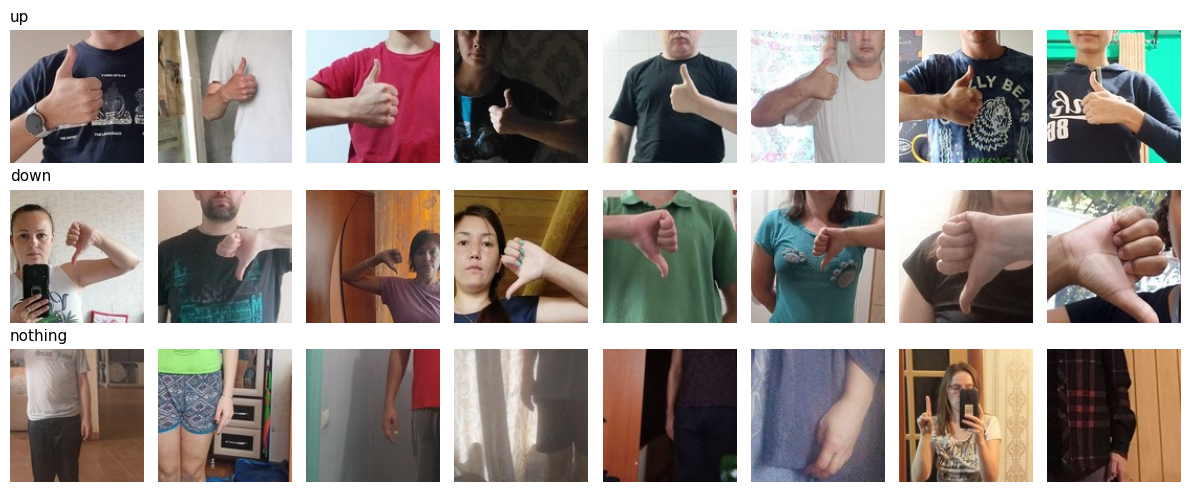

In [74]:
web_files = sorted(Path("web_sample").glob("*/*.jpg"))
Xw = np.stack([imread_u(f) for f in web_files])
yw = np.array([CLASSES.index(f.parent.name) for f in web_files])
print(f"{len(Xw)} photos:", {CLASSES[k]: int((yw == k).sum()) for k in np.unique(yw)})

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
for row, k in zip(axes, np.unique(yw)):
    for ax, i in zip(row, np.where(yw == k)[0][::4]):
        ax.imshow(Xw[i][..., ::-1])
        ax.axis("off")
    row[0].set_title(CLASSES[k], loc="left", fontsize=11)
plt.tight_layout()
plt.show()

Two baselines before any model: guessing among 5 classes gets **20%**, and a model that always
answers "nothing" gets **one third** - 30 of the 90 photos are "nothing". A model has to beat both.
Now every model from this notebook on the strangers:

In [75]:
# ~25 s: ResNet-18 and CLIP features of the 90 photos
Fw = features(Xw)                                               # ResNet-18 features
Cw = clip_features(Xw)                                          # CLIP embeddings
acc_web = {"plain ANN": (predict(ann, Xw) == yw).mean(),
           "small CNN": (predict(cnn, Xw) == yw).mean(),
           "bigger CNN": (predict(big, Xw) == yw).mean(),
           "bigger CNN + augmentation": (predict(big_aug, Xw) == yw).mean(),
           "ResNet-18 probe": (probe.predict(Fw) == yw).mean(),
           "ResNet-18 fine-tuned (LP-FT)": (predict(ft, Xw) == yw).mean(),
           "ResNet-18 fine-tuned (random head)": (predict(ft_rand, Xw) == yw).mean(),
           "CLIP probe": clip_probe.score(Cw, yw),
           "CLIP zero-shot": (zero_shot(Cw) == yw).mean()}
always_nothing = (yw == CLASSES.index("nothing")).mean()
for name, acc in acc_web.items():
    print(f"{name:<34} {acc:6.1%}")
print(f"{'always nothing':<34} {always_nothing:6.1%}")

plain ANN                           23.3%
small CNN                           17.8%
bigger CNN                          21.1%
bigger CNN + augmentation           17.8%
ResNet-18 probe                     44.4%
ResNet-18 fine-tuned (LP-FT)        42.2%
ResNet-18 fine-tuned (random head)  35.6%
CLIP probe                          43.3%
CLIP zero-shot                      41.1%
always nothing                      33.3%


In [76]:
fig = go.Figure(go.Bar(x=list(acc_web), y=list(acc_web.values()),
                       marker_color=[ARM_BLUE] * 4 + ["#2E8B57"] * 3 + [ARM_ORANGE] * 2,
                       text=[f"{v:.1%}" for v in acc_web.values()], textposition="outside"))
fig.add_hline(y=1 / len(CLASSES), line_dash="dot", line_color="gray",
              annotation_text="guessing (20%)", annotation_position="bottom right")
fig.add_hline(y=always_nothing, line_dash="dash", line_color=ARM_RED,
              annotation_text="always 'nothing' (33.3%)", annotation_position="top right")
fig.update_layout(height=440, width=900, yaxis=dict(range=[0, 1.1], title="accuracy on strangers",
                  tickformat=".0%"), margin=dict(t=20))
fig.show()

What the ResNet-18 probe answers for each stranger - the title is its answer, red when wrong:

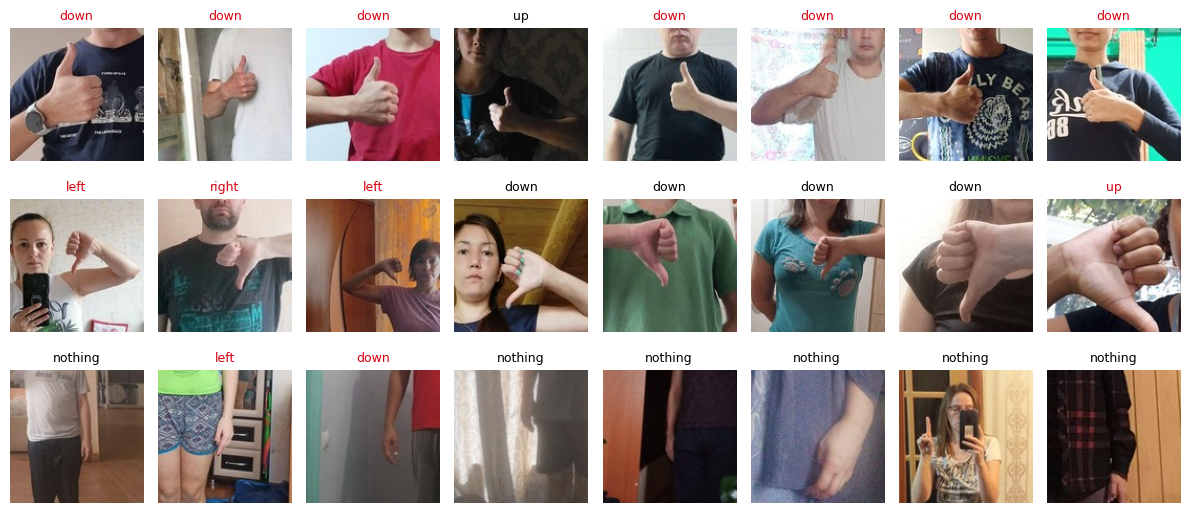

predicted,up,down,left,right,nothing
true,,,,,
up,2,22,3,0,3
down,1,22,5,1,1
nothing,0,11,1,2,16


In [77]:
pred_web = probe.predict(Fw)
fig, axes = plt.subplots(3, 8, figsize=(12, 5.4))
for row, k in zip(axes, np.unique(yw)):
    for ax, i in zip(row, np.where(yw == k)[0][::4]):
        ax.imshow(Xw[i][..., ::-1])
        ax.set_title(CLASSES[pred_web[i]], fontsize=9, color="black" if pred_web[i] == k else ARM_RED)
        ax.axis("off")
    row[0].set_ylabel(CLASSES[k])
plt.tight_layout()
plt.show()
confusion(pred_web, yw).loc[[CLASSES[k] for k in np.unique(yw)]]

**On the instructor's recordings** every network trained from scratch stays below the "always
nothing" line: 17.8% to 23.3% - including the augmented bigger CNN, the best of them on your own
validation bursts, at 17.8% here. The borrowed models clear it, and the three ResNet-18 models
finish Part 8b's story:

| ResNet-18 | your validation bursts | strangers |
|---|---|---|
| frozen probe (Part 8) | 64.0% | 44.4% |
| fine-tuned from the probe (LP-FT) | 76.0% | 42.2% |
| fine-tuned from a random head | 82.8% | 35.6% |

The more a model bent its features towards your room, the better it did there and the worse on
strangers. The random-head model, the best of the three on your bursts, is barely above "always
nothing" (33.3%) here; LP-FT keeps most of the probe's score. The gap is 6 photos out of 90 - a
hint, not proof - but it is the pattern of [50]'s LP-FT slide, which Kumar et al. measured on 10
datasets: fine-tuning from a random head wins on data like the training data and loses on shifted
data. CLIP gets there with no fine-tuning at all: its probe 43.3%, and zero-shot 41.1% without a
single training crop.

The grid shows the ResNet-18 probe's favourite mistake: 22 of the 30 strangers giving a thumbs
**up** are called "down". Look at the photos: a person, a shirt, a thumb in front of the chest - a
framing your training crops never had. Why "down" in particular is hard to say from 90 photos; the
safe lesson is the general one.

Trained on one person in one room, a model knows that person and that room. That is why everyone
trains on their own recordings - and why a game for many players would need recordings from many
players.

## Part 11 - export and play

`torch.export` saves the model **with its computation graph**, so `play_snake.py` can load it
without knowing the class you wrote here. The contract (see `gesture_common.py`): a
`(N, 3, 128, 128)` RGB tensor in `[0, 1]` in, 5 logits out.

Export records the shapes of the example you give it. Marking dimension 0 as `Dim.DYNAMIC`
keeps the batch size free; the example holds **2** crops because with 1, export decides the
batch size is a constant and refuses.

In [78]:
def export(model, path):
    model.eval()
    example = torch.zeros(2, 3, CROP_SIZE, CROP_SIZE)
    ep = torch.export.export(model, (example,), dynamic_shapes=({0: torch.export.Dim.DYNAMIC},))
    torch.export.save(ep, path)

The ResNet-18 probe is two objects - a torch trunk and an sklearn logistic regression. To export it,
copy the regression's weights into an `nn.Linear` (a logistic regression **is** one linear layer
plus softmax, [11]) and put ImageNet's normalization inside the model, where the contract wants it.

In [79]:
# ~6 s
class ResNetProbe(nn.Module):
    def __init__(self, trunk, probe):
        super().__init__()
        if list(probe.classes_) != list(range(len(CLASSES))):
            raise ValueError(f"probe classes {probe.classes_} do not match CLASSES")
        self.trunk = trunk
        self.head = nn.Linear(512, len(CLASSES))
        with torch.no_grad():
            self.head.weight.copy_(torch.from_numpy(probe.coef_).float())
            self.head.bias.copy_(torch.from_numpy(probe.intercept_).float())
        self.register_buffer("mean", MEAN.clone())
        self.register_buffer("std", STD.clone())

    def forward(self, x):
        return self.head(self.trunk((x - self.mean) / self.std))


resnet_model = ResNetProbe(trunk, probe).eval()
agree = (predict(resnet_model, X[va]) == probe.predict(F_va)).mean()
assert agree > 0.99, f"the torch copy of the probe disagrees with sklearn on {1 - agree:.1%} of crops"
print(f"torch copy agrees with sklearn on {agree:.1%} of validation crops")

torch copy agrees with sklearn on 100.0% of validation crops


Export the four candidates. `gesture_model.pt2` - the file the game loads by default - is
whichever scored highest on the held-out bursts; the others stay available with
`python play_snake.py --model ...`.

In [80]:
# ~45 s: exporting and re-checking four models (measured 43 s)
import shutil
from play_snake import load_model

candidates = {"gesture_model_cnn.pt2": (cnn, acc_cnn),
              "gesture_model_bigcnn.pt2": (big_aug, acc_aug),           # the augmented one, Part 6
              "gesture_model_resnet.pt2": (resnet_model, acc_probe),
              "gesture_model_finetuned.pt2": (ft, acc_ft)}                 # LP-FT, Part 8b
for path, (model, acc) in candidates.items():
    export(model, path)
    reloaded = load_model(Path(path))
    with torch.no_grad():
        same = (reloaded(bgr_to_tensor(X[va])).argmax(1).numpy() == predict(model, X[va])).mean()
    assert same > 0.99, f"{path}: the exported model disagrees with the original on {1 - same:.1%} of crops"
    print(f"{path}: validation {acc:.1%}, exported copy agrees on {same:.1%}")
best = max(candidates, key=lambda p: candidates[p][1])
shutil.copyfile(best, "gesture_model.pt2")
print(f"gesture_model.pt2 <- {best}")

C:\Users\hayk_\OneDrive\Desktop\01_python_math_ml_course\ma\Lib\site-packages\torch\export\pt2_archive\_package.py:682: UserWarning:

The given buffer is not writable, and PyTorch does not support non-writable tensors. This means you can write to the underlying (supposedly non-writable) buffer using the tensor. You may want to copy the buffer to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:1587.)



gesture_model_cnn.pt2: validation 46.0%, exported copy agrees on 100.0%


gesture_model_bigcnn.pt2: validation 66.0%, exported copy agrees on 100.0%


gesture_model_resnet.pt2: validation 64.0%, exported copy agrees on 100.0%


gesture_model_finetuned.pt2: validation 76.0%, exported copy agrees on 100.0%
gesture_model.pt2 <- gesture_model_finetuned.pt2


**On the instructor's recordings** the default is the fine-tuned ResNet-18 (LP-FT, Part 8b):
76.0% on the held-out bursts, ahead of the augmented bigger CNN (66.0%) and the frozen probe
(64.0%) - and 42.2% on strangers, where the bigger CNN fell to 17.8%. The random-head model is not
exported: Part 10 showed what its 82.8% costs. The price of the default is speed: a whole ResNet-18,
59.6 ms per frame in Part 8, so the game runs at a lower frame rate. If it feels sluggish, the
bigger CNN needs 8.3 ms.

Now play:

```
python play_snake.py
python play_snake.py --model gesture_model_bigcnn.pt2
```